# Descriptor-conditioned generation of boiling frames

**What.** Given a compact physical descriptor θ — the void fraction, mean temperature and
hot-wall fraction of five wall-normal regions, the Sauter mean bubble diameter D32, the
bubble count, and the wall temperature — a convolutional generator renders the full
two-dimensional frame (level-set field `dfun` and temperature `T`, 288 × 192) that the
descriptor asks for. It is trained on 30 015 frames from 15 simulations of the BubbleML
boiling corpus: eleven single-bubble cases (wall 10–26 °C) and four developed-boiling
cases (75–107 °C).

**Why.** A pixel-supervised generator of boiling faces two obstacles: the corpus is small,
and pixel losses *average* over the many admissible bubble placements, which rewards blur.
The quantities an engineer can actually measure — void fractions, bubble sizes, hot spots —
live in a 13-dimensional space. We therefore make that space the interface and judge the
generator by the **round-trip (RT)**: render a frame, re-run the exact descriptor extraction
used on the data, and require the recovered θ to equal the ask. Pixel losses are retained as
anchors but are informational.

**Reference points.** *Retrieval* (M2) returns the nearest descriptor neighbour from the
training set — a real frame with perfect pixels, no flexibility, and one full frame in memory
per entry. `real(next)` hands a real frame the *next* real frame's descriptor; its 3.9 % test
error is the information floor set by the simulation's own dynamics. In this run the
generator reaches an 11.7 % round-trip (9.9 % with a per-column affine correction) on wall
temperatures it never trained on, with sharp, artifact-free frames (edge energy 0.96
versus 1.0 for real frames).

**Scope.** This notebook is the decoder half of a two-stage surrogate: the companion
forecasting notebook evolves θ(t) forward in time and exports trajectories as decoder
asks; this notebook renders any descriptor as a frame.

*Requirements:* `torch`, `h5py`, `numpy`, `scipy`, `pandas`, `matplotlib`. Point
`CFG['DATA_DIR']` at the folder holding the `.h5` files and run top to bottom (the executed
run: 154 epochs, ≈ 77 GPU-hours). Every tunable is a `CFG` key; code bodies contain no magic
numbers. Artifacts land in `OUT_DIR` (printed at the end).

In [2]:
# ============================================================================
# CELL 1 · configuration, file discovery, loading, theta extraction
# ----------------------------------------------------------------------------
# Decisions worth knowing about:
#  * every tunable is a key of CFG - the code body contains no magic numbers;
#  * files are discovered by glob, so dropping a third .h5 into DATA_DIR is
#    enough to widen the corpus (P4) - nothing else has to change;
#  * case-level scalars (wallTemp, ...) are auto-detected: any numeric scalar
#    that exists in all files and actually varies becomes a conditioning
#    column, so the decoder input widens by itself when conditions are added;
#  * ONE extractor (extract_theta) is used for real AND generated frames -
#    that is what makes the round-trip well-defined;
#  * normalization statistics are computed on the TRAIN split only (no leakage);
#  * v2 splits are WHOLE FILES (one experiment = one file), stratified by boiling
#    regime and dealt across the wallTemp-sorted order so each split spans the
#    condition range -> every val/test condition is NEVER trained on (cross-
#    condition by construction), matching the FC forecaster's split convention.
# ============================================================================
import os, re, glob, math, time, warnings
import numpy as np
import pandas as pd
import h5py
from scipy import ndimage
from scipy import stats as sps

warnings.filterwarnings('ignore')

CFG = dict(
    # ---------------- data discovery / loading ----------------
    DATA_DIR        = r'G:\BoilDesc',      # folder that holds the .h5 files (searched recursively)
    OUT_SUBDIR      = 'src',               # artifacts go to DATA_DIR/OUT_SUBDIR if it exists
    KEY_DFUN        = 'dfun',              # exact dataset name first, fuzzy 3-D match as fallback
    KEY_T           = 'temperature',
    WTEMP_ATTRS     = ('wall_temperature', 'wallTemp', 'wall_temp'),
    WTEMP_FN_REGEX  = r'twall[_-]?(\d+(?:\.\d+)?)',   # fallback: parse the file name
    DT_ATTRS        = ('dt', 'time_step', 'deltaT'),
    DT_DEFAULT      = 0.1,                 # s, used only if the file says nothing
    FRAME_STRIDE    = 1,                   # keep every k-th frame (RAM relief)
    FRAME_LIMIT     = None,                # int: cap frames per file (debug runs)
    ALLOW_CROP      = True,                # centre-crop if files differ in shape
    CASE_OVERRIDE   = {},                  # {'Twall_95': {'wallTemp': 95.0}, ...} manual pinning
    EXTRA_INCLUDE   = [],                  # force these case scalars into the conditioning
    EXTRA_EXCLUDE   = [],                  # ... and keep these out
    MAX_EXTRA       = 8,                   # cap on auto-detected case scalars
    # ---------------- descriptor / segmentation ----------------
    # keep these equal to your M3 extractor conventions so numbers stay comparable!
    N_REGIONS       = 5,
    REGION_AXIS     = 'y',                 # 'y' horizontal layers / 'x' vertical bands
    REGION_FLIP     = False,               # True if M3 numbered regions the other way round
    TAU_DFUN        = 0.0,                 # gas where dfun > TAU
    T_HOT_MODE      = 'wall_minus_margin', # or 'absolute'
    T_HOT_MARGIN    = 5.0,                 # degC below wall temperature counts as hot
    T_HOT_ABS       = 65.0,                # used when T_HOT_MODE = 'absolute'
    T_MEAN_LIQUID   = False,               # True: Tmean over liquid pixels only
    MIN_BUB_PIX     = 6,                   # smaller connected components are treated as noise
    LIVE_STD_TH     = 1e-6,                # theta column is "live" if its std exceeds this
    # ---------------- model (P0 / P2) ----------------
    MIN_LAT         = 8,                   # latent grid >= MIN_LAT per side (sets the depth)
    LAT_CH          = 96,                  # M3 used 64 - wider on purpose (P2)
    CHS_EXTRA       = [128, 96, 64, 48],
    Z_DIM           = 0,                   # 0 = deterministic decoder (RT-friendly)
    CLIP_B          = 4.0,                 # sigma: soft penalty above this (P0)
    CLIP_INF        = 6.0,                 # sigma: hard clamp at inference (P0)
    EMA_DECAY       = 0.999,
    # ---------------- training ----------------
    EPOCHS          = 500,                  # M3 was still improving when it stopped at 20
    BATCH           = 16,
    LR              = 2e-4,
    WEIGHT_DECAY    = 1e-5,
    GRAD_CLIP       = 1.0,
    WARMUP_EPOCHS   = 2,
    PATIENCE        = 15,                  # early stop on no-CAL val RT (the honest metric)
    EVAL_EVERY      = 2,
    EVAL_N          = 48,                  # frames per quick RT during training
    CAL_FIT_N       = 64,                  # train frames to fit CAL during training
    LOSS_W          = dict(pix=1.0, hf=1.0, rt=8.0, gran=8.0, stab=0.5, knob=1.0),
    SOFT_D          = 0.10,                # dfun soft-threshold width (physical units)
    SOFT_T          = 0.50,                # T    soft-threshold width (degC)
    # ---------------- splits / evaluation (v2: FILE-LEVEL, matches the FC forecaster) ----
    SPLIT_LEVEL     = 'file',              # v2: ONE split label per WHOLE file
    TRAIN_FRAC      = 0.50,                # target fraction of FILES per split
    VAL_FRAC        = 0.25,                # (counts adapt to the file count; every split
    TEST_FRAC       = 0.25,                #  keeps at least one file; needs >= 3 files)
    BOILING_TWALL_MIN = 70.0,              # wallTemp >= this -> 'boiling', else 'single_bubble';
                                           # splits are STRATIFIED by this regime
    CATEGORY_OVERRIDE = {},                # {'Twall_75': 'boiling', ...} manual pinning
    SEED            = 0,
    # ---------------- reporting (P3) ----------------
    FIT_N           = 512,                 # train frames for the final CAL fit + fit-gap
    D32_CAL_N       = 256,                 # frames for the D32 surrogate calibration
    DIAG_N          = 64,                  # frames for the image diagnostics
    N_EXAMPLES      = 3,                   # best / median / worst test frames
    ZOOM            = 64,                  # px side of the zoomed example patch
    CONTROL_DELTA   = 0.25,                # sigma size of the control-matrix ask
    KNOB_N          = 8,                   # knob-consistency sub-batch size (F4 fix)
    KNOB_DELTA      = 0.25,                # sigma size of the synthetic single-knob ask
    BLOWUP_K        = 5.0,                 # RT > K x median -> blow-up frame
    HF_CUT          = 0.25,                # cycles/px: "high frequency" above this
    DPI             = 150,
)
SEED = CFG['SEED']
np.random.seed(SEED)

# ------------------------- file discovery (P4) ------------------------------
def find_files(root):
    """every .h5/.hdf5 under root, minus venv/internal noise - adding a file
    to this folder is all it takes to grow the corpus."""
    bad = ('.venv', 'site-packages', '__pycache__', '.git')
    out = []
    for pat in ('*.h5', '*.hdf5'):
        out += glob.glob(os.path.join(root, '**', pat), recursive=True)
    return sorted({os.path.normpath(p) for p in out if not any(b in p for b in bad)})

FILES = find_files(CFG['DATA_DIR'])
assert FILES, f"no .h5 files under {CFG['DATA_DIR']} - set CFG['DATA_DIR']"
print(f"[data] {len(FILES)} file(s) discovered under {CFG['DATA_DIR']}")

# show the layout of the first file so key mismatches are visible immediately
with h5py.File(FILES[0], 'r') as _f:
    _lay = {k: (tuple(_f[k].shape) if isinstance(_f[k], h5py.Dataset) else 'group')
            for k in _f.keys()}
    print(f"[layout] {os.path.basename(FILES[0])}: datasets={_lay}")
    print(f"[layout] attrs={ {k: (v if np.ndim(v) == 0 else np.asarray(v).ravel()[:4]) for k, v in _f.attrs.items()} }")

# ------------------------- schema helpers -----------------------------------
def as_float(v):
    """numeric scalar or None (strings / arrays / compound junk -> None)."""
    try:
        a = np.asarray(v)
        if a.dtype.kind in 'US':  return None
        a = np.ravel(a)
        return float(a[0]) if a.size == 1 else None
    except Exception:
        return None

def scalar_candidates(f):
    """numeric scalars from attrs + ()/(1,) root datasets - the case-level pool."""
    out = {}
    for k, v in f.attrs.items():
        x = as_float(v)
        if x is not None:
            out[k] = x
    for k in f.keys():
        try:
            d = f[k]
            if isinstance(d, h5py.Dataset) and d.ndim <= 1 and d.size <= 1:
                x = as_float(d[()])
                if x is not None and k not in out:
                    out[k] = x
        except Exception:
            pass
    return out

def find_dfun_key(f):
    k = CFG['KEY_DFUN']
    if k in f.keys() and f[k].ndim == 3:
        return k
    for k in f.keys():
        if (isinstance(f[k], h5py.Dataset) and f[k].ndim == 3
                and 'dfun' in k.lower()):
            return k
    return None

def find_T_key(f):
    cand = [k for k in f.keys()
            if isinstance(f[k], h5py.Dataset) and f[k].ndim == 3
            and 'temp' in k.lower()]
    # prefer the plain 'temperature' dataset, avoid wall/sat/subcool variants
    cand.sort(key=lambda k: (k.lower() != 'temperature',
                             any(w in k.lower() for w in ('wall', 'sat', 'subcool'))))
    return cand[0] if cand else None

def walltemp_of(path, sc):
    """wall temperature: named attr -> any wall*temp attr -> file-name regex."""
    for name in CFG['WTEMP_ATTRS']:
        for k in sc:
            if k.lower() == name.lower():
                return sc[k], k
    for k, v in sc.items():
        if 'wall' in k.lower() and 'temp' in k.lower():
            return v, k
    m = re.search(CFG['WTEMP_FN_REGEX'], os.path.basename(path), re.I)
    if m:
        return float(m.group(1)), 'filename'
    return float('nan'), None

def load_file(path):
    with h5py.File(path, 'r') as f:
        kd, kt = find_dfun_key(f), find_T_key(f)
        if kd is None or kt is None:
            raise RuntimeError(
                f"{path}: could not locate 3-D dfun/temperature datasets "
                f"(keys={list(f.keys())}). Adjust CFG['KEY_DFUN']/CFG['KEY_T'].")
        d = np.asarray(f[kd], dtype=np.float32)     # (Nt,H,W)
        T = np.asarray(f[kt], dtype=np.float32)
        if d.ndim == 4: d = d[:, 0]                  # tolerate (Nt,1,H,W)
        if T.ndim == 4: T = T[:, 0]
        if d.shape != T.shape:
            raise RuntimeError(f"{path}: dfun {d.shape} vs T {T.shape} mismatch")
        sc = scalar_candidates(f)
    return kd, kt, d, T, sc

RAW = {}
for p in FILES:
    stem = os.path.splitext(os.path.basename(p))[0]
    kd, kt, d, T, sc = load_file(p)
    sc.update({k: float(v) for k, v in CFG['CASE_OVERRIDE'].get(stem, {}).items()})
    wt, wt_src = walltemp_of(p, sc)
    dt = next((sc[a] for a in CFG['DT_ATTRS'] if a in sc), CFG['DT_DEFAULT'])
    RAW[stem] = dict(path=p, dfun=d, T=T, sc=sc, wallTemp=wt, dt=dt)
    print(f"  {stem:24s} {str(d.shape):14s} keys=({kd},{kt})  "
          f"wallTemp={wt:g} ({wt_src})  dt={dt:g}s")

assert len(RAW) >= 1, 'no loadable files'

# ------------------------- common frame shape -------------------------------
Hs = [v['dfun'].shape[1] for v in RAW.values()]
Ws = [v['dfun'].shape[2] for v in RAW.values()]
if len(set(zip(Hs, Ws))) > 1:
    if not CFG['ALLOW_CROP']:
        raise RuntimeError(f"files differ in shape {set(zip(Hs, Ws))} - allow ALLOW_CROP or fix data")
    H, W = min(Hs), min(Ws)
    print(f"[crop] frame shapes differ -> centre-cropping everything to {H}x{W}")
else:
    H, W = Hs[0], Ws[0]

def centre_crop(a, H_, W_):
    h, w = a.shape[-2:]
    if (h, w) == (H_, W_):
        return a
    y0, x0 = (h - H_) // 2, (w - W_) // 2
    return a[..., y0:y0 + H_, x0:x0 + W_]

# ------------------------- the round-trip extractor -------------------------
def build_regions(H_, W_):
    """equal bands along REGION_AXIS; region 1 = first band along that axis.
    REGION_FLIP reverses the numbering (match your M3 convention here)."""
    n = CFG['N_REGIONS']
    if CFG['REGION_AXIS'] == 'y':
        e = np.linspace(0, H_, n + 1).astype(int)
        sl = [(slice(e[r], e[r + 1]), slice(0, W_)) for r in range(n)]
    else:
        e = np.linspace(0, W_, n + 1).astype(int)
        sl = [(slice(0, H_), slice(e[r], e[r + 1])) for r in range(n)]
    return sl[::-1] if CFG['REGION_FLIP'] else sl

REG_SLICES = build_regions(H, W)

def extract_theta(dfun, T, t_hot):
    """THE descriptor extractor - one code path for real and generated frames.
    That single fact is what makes the round-trip well-defined."""
    mask = dfun > CFG['TAU_DFUN']
    out = {}
    for r, (sy, sx) in enumerate(REG_SLICES, 1):
        m_r = mask[sy, sx]
        T_r = T[sy, sx]
        out[f'alpha_{r}'] = float(m_r.mean())
        if CFG['T_MEAN_LIQUID']:
            w = (~m_r).astype(np.float32)
            out[f'Tmean_{r}'] = float((T_r * w).sum() / max(w.sum(), 1.0))
        else:
            out[f'Tmean_{r}'] = float(T_r.mean())
        out[f'f_hot_{r}'] = float((T_r > t_hot).mean())
    lab, nb = ndimage.label(mask)                     # D32 + nbub from 2-D components
    if nb:
        areas = np.bincount(lab.ravel())[1:]
        areas = areas[areas >= CFG['MIN_BUB_PIX']]
        out['nbub'] = int(len(areas))                 # bubble count (nucleation column)
        if len(areas):
            d_eq = 2.0 * np.sqrt(areas / np.pi)       # equivalent diameters, px
            out['D32'] = float((d_eq ** 3).sum() / max((d_eq ** 2).sum(), 1e-9))
        else:
            out['D32'] = 0.0
    else:
        out['nbub'] = 0
        out['D32'] = 0.0
    return out

def t_hot_of(wallTemp, T_all):
    """hot threshold per condition - 'within MARGIN of the wall' travels with the
    data (works for any wall temperature), 'absolute' pins one number."""
    if CFG['T_HOT_MODE'] == 'absolute':
        return float(CFG['T_HOT_ABS'])
    if np.isfinite(wallTemp):
        return float(wallTemp - CFG['T_HOT_MARGIN'])
    return float(T_all.mean() + T_all.std())          # fallback: hot tail

# ------------------------- v2: FILE-LEVEL split assignment -------------------
# Whole files -> train/val/test, stratified by boiling regime (boiling vs
# single_bubble from wallTemp) so a split never silently loses a whole physics
# regime, and dealt across the wallTemp-sorted order so each split spans the
# condition range. Mirrors the FC forecaster's split convention exactly.
def category_of(stem):
    if stem in CFG.get('CATEGORY_OVERRIDE', {}):
        return str(CFG['CATEGORY_OVERRIDE'][stem])
    wt = float(RAW[stem]['wallTemp'])
    return 'boiling' if np.isfinite(wt) and wt >= CFG['BOILING_TWALL_MIN'] else 'single_bubble'

def split_counts(m):
    """(train, val, test) file counts for one category holding m files."""
    if m <= 0: return (0, 0, 0)
    if m == 1: return (1, 0, 0)                       # too few to hold out - train on it
    if m == 2: return (1, 1, 0)
    c_tr = max(1, int(round(CFG['TRAIN_FRAC'] * m)))
    c_va = max(1, int(round(CFG['VAL_FRAC'] * m)))
    c_tr = min(c_tr, m - 2)                           # leave room for >= 1 val, >= 1 test
    c_va = min(c_va, m - c_tr - 1)
    return (c_tr, c_va, m - c_tr - c_va)

def deal_files(stems_sorted, counts):
    """deal wallTemp-sorted files to splits: largest remaining need first, ties
    to the least recently served split -> each split spans the condition range."""
    need = dict(zip(('train', 'val', 'test'), counts))
    last = {k: -1 for k in need}
    out = {}
    for i, s in enumerate(stems_sorted):
        cand = [k for k in ('train', 'val', 'test') if need[k] > 0]
        k = sorted(cand, key=lambda q: (-need[q], last[q]))[0]
        out[s] = k; need[k] -= 1; last[k] = i
    return out

def repair_empty_splits(assign, wt_of):
    """global guarantee: with >= 3 files every split holds at least one file."""
    for role in ('val', 'test'):
        while not [s for s in assign if assign[s] == role]:
            pool = max(('train', 'val', 'test'),
                       key=lambda r: sum(v == r for v in assign.values()))
            cand = [s for s in assign if assign[s] == pool]
            wts = sorted(wt_of(s) for s in assign if np.isfinite(wt_of(s)))
            med = wts[len(wts) // 2] if wts else np.inf
            mv = min(cand, key=lambda s: (abs(wt_of(s) - med)
                                          if np.isfinite(wt_of(s)) else np.inf, s))
            assign[mv] = role
            print(f"[split] repair: moved '{mv}' -> {role} (split was empty)")
    return assign

assert len(RAW) >= 3, ("file-level splits need >= 3 files (one per split) - "
                       f"got {len(RAW)}; add .h5 files to DATA_DIR")
CATS = {s: category_of(s) for s in RAW}
ASSIGN = {}
for cat in sorted(set(CATS.values())):
    stems = sorted([s for s in RAW if CATS[s] == cat],
                   key=lambda s: (float(RAW[s]['wallTemp'])
                                  if np.isfinite(float(RAW[s]['wallTemp'])) else np.inf, s))
    ASSIGN.update(deal_files(stems, split_counts(len(stems))))
_wt_of = lambda s: (float(RAW[s]['wallTemp'])
                    if np.isfinite(float(RAW[s]['wallTemp'])) else np.inf)
FILE_SPLIT = repair_empty_splits(ASSIGN, _wt_of)
print(f"[split] v2 FILE-LEVEL splits (target {CFG['TRAIN_FRAC']:.0%}/"
      f"{CFG['VAL_FRAC']:.0%}/{CFG['TEST_FRAC']:.0%} of the {len(RAW)} files, "
      f"stratified by regime):")
for r in ('train', 'val', 'test'):
    sts = sorted([s for s in FILE_SPLIT if FILE_SPLIT[s] == r], key=_wt_of)
    print(f"[split] {r:5s} ({len(sts)} file(s))"
          + (f", wallTemp {_wt_of(sts[0]):g}..{_wt_of(sts[-1]):g}" if len(sts) >= 2 else "")
          + f": {', '.join(s.replace('Twall_', '') for s in sts)}")
for cat in sorted(set(CATS.values())):
    print(f"[split] category '{cat}': {sum(v == cat for v in CATS.values())} file(s)")

# ------------------------- load frames, build theta table -------------------
rows, DATA, SPLIT_POS = [], {}, {}
for stem, v in RAW.items():
    Nt = v['dfun'].shape[0]
    kept = list(range(0, Nt, CFG['FRAME_STRIDE']))[: CFG['FRAME_LIMIT'] or Nt]
    assert len(kept) > 0, f"{stem}: no frames after stride/limit"
    d = np.ascontiguousarray(centre_crop(v['dfun'][kept], H, W))
    T = np.ascontiguousarray(centre_crop(v['T'][kept], H, W))
    th_ = t_hot_of(v['wallTemp'], v['T'])
    splits = [FILE_SPLIT[stem]] * len(kept)          # v2: ONE split label per WHOLE file
    DATA[stem] = dict(dfun=d, T=T, dt=v['dt'], wallTemp=v['wallTemp'],
                      t_hot=th_, sc=v['sc'], n=len(kept))
    SPLIT_POS[stem] = np.array(splits)
    for pos in range(len(kept)):
        th = extract_theta(d[pos], T[pos], th_)
        r = dict(file=stem, pos=pos, frame=kept[pos], t=kept[pos] * v['dt'],
                 split=splits[pos], T_HOT=th_, wallTemp=v['wallTemp'], **th)
        r.update(v['sc'])
        rows.append(r)

FRAME_COLS = ([f'alpha_{r}'  for r in range(1, CFG['N_REGIONS'] + 1)]
              + [f'Tmean_{r}' for r in range(1, CFG['N_REGIONS'] + 1)]
              + [f'f_hot_{r}' for r in range(1, CFG['N_REGIONS'] + 1)]
              + ['D32', 'nbub'])
_head = ['file', 'pos', 'frame', 't', 'split', 'T_HOT']
ROWS = pd.DataFrame(rows)
ROWS = ROWS[[c for c in _head if c in ROWS.columns] + FRAME_COLS
            + [c for c in ROWS.columns if c not in _head + FRAME_COLS]]
ROWS = ROWS.reset_index(drop=True)
del RAW                                                # free the unstrided copies

# ------------------------- cross-condition by construction (v2) --------------
# With whole-file splits the test files are conditions that were NEVER trained
# on, so the test leaderboard number IS the cross-condition headline. The
# explicit xval hold-out of v1 is retired (it was consumed by the CELL 3 split
# repair anyway); CELL 6 surfaces the per-held-out-file breakdown as the headline.
XVSTEM = None

# ------------------------- live / extra column detection --------------------
stds = ROWS[FRAME_COLS].std()
LIVE_COLS = [c for c in FRAME_COLS if stds[c] > CFG['LIVE_STD_TH']]
DEAD_COLS = [c for c in FRAME_COLS if c not in LIVE_COLS]
assert LIVE_COLS, 'no live descriptor columns - check the thresholds in CFG'

AUTO_EXTRA_RE  = re.compile(r'temp|heat|flux|grav|subcool|angle|pressure|veloc|super|dens|conduct', re.I)
AUTO_EXTRA_BAD = re.compile(r'^t$|time|dt$|step|frame|final|n_?t|count|iter', re.I)
_scols = [c for c in ROWS.columns
          if c not in _head + FRAME_COLS and ROWS[c].dtype.kind == 'f']
_cand = [c for c in _scols if ROWS[c].notna().all() and ROWS[c].nunique() >= 2]
keep = []
for c in _cand:
    if c in CFG['EXTRA_INCLUDE']:
        keep.append(c)
    elif c in CFG['EXTRA_EXCLUDE'] or AUTO_EXTRA_BAD.search(c):
        continue
    elif AUTO_EXTRA_RE.search(c):
        keep.append(c)
if 'wallTemp' in keep:                                  # de-duplicate wallTemp vs its attr twin
    for other in list(keep):
        if other != 'wallTemp' and re.search(r'wall', other, re.I) and re.search(r'temp', other, re.I):
            g = ROWS.groupby('file').agg(a=('wallTemp', 'first'), b=(other, 'first'))
            if (g['a'] == g['b']).all():
                keep.remove('wallTemp')
                break
if len(keep) > CFG['MAX_EXTRA']:
    dropped = keep[CFG['MAX_EXTRA']:]
    keep = keep[:CFG['MAX_EXTRA']]
    print(f"[extra] capping conditioning scalars at {CFG['MAX_EXTRA']} (dropped {dropped})")
EXTRA_COLS = keep
COND_COLS = LIVE_COLS + EXTRA_COLS
COL2COND = {c: j for j, c in enumerate(COND_COLS)}
LIVE_SET = set(LIVE_COLS)
LIVE_IDX = np.array([c in LIVE_SET for c in FRAME_COLS])

# ------------------------- normalization (train only) -----------------------
tr_mask = (ROWS.split == 'train').values
_s = np.zeros(2, np.float64); _q = np.zeros(2, np.float64); _n = 0
for stem, dd in DATA.items():
    sp = SPLIT_POS[stem] == 'train'
    d, T = dd['dfun'][sp], dd['T'][sp]
    _s[0] += d.sum(); _q[0] += (d.astype(np.float64) ** 2).sum()
    _s[1] += T.sum(); _q[1] += (T.astype(np.float64) ** 2).sum()
    _n += d.size
NORM = dict(mu_d=float(_s[0] / _n), mu_T=float(_s[1] / _n))
NORM['sd_d'] = max(math.sqrt(_q[0] / _n - NORM['mu_d'] ** 2), 1e-6)
NORM['sd_T'] = max(math.sqrt(_q[1] / _n - NORM['mu_T'] ** 2), 1e-6)

tr_rows = ROWS[tr_mask]
TH_MU, TH_SD = {}, {}
for c in FRAME_COLS + EXTRA_COLS:
    TH_MU[c] = float(tr_rows[c].mean())
    TH_SD[c] = max(float(tr_rows[c].std()), 1e-9)
TH_TRUE = ROWS[FRAME_COLS].values.astype(np.float32)
LIVE_SD = np.array([TH_SD[c] for c in LIVE_COLS], np.float32)
MU_F = np.array([TH_MU[c] for c in FRAME_COLS], np.float64)
SD_F = np.array([max(TH_SD[c], 1e-9) for c in FRAME_COLS], np.float64)
Xc = ROWS[COND_COLS].values.astype(np.float64)
COND_Z = ((Xc - np.array([TH_MU[c] for c in COND_COLS]))
          / np.array([TH_SD[c] for c in COND_COLS])).astype(np.float32)

WTEMP_COND_COL = next((c for c in COND_COLS
                       if re.search(r'wall', c, re.I) and re.search(r'temp', c, re.I)), None)

def t_hot_of_cond(cz):
    """recover a row's hot threshold from its conditioning vector (z space).
    Guaranteed recoverable: the threshold is absolute, or a function of the
    wall temperature, which is a conditioning column whenever it varies."""
    if CFG['T_HOT_MODE'] == 'absolute':
        return float(CFG['T_HOT_ABS'])
    if WTEMP_COND_COL is not None:
        j = COL2COND[WTEMP_COND_COL]
        wt = float(cz[j]) * TH_SD[WTEMP_COND_COL] + TH_MU[WTEMP_COND_COL]
        return float(wt - CFG['T_HOT_MARGIN'])
    return float(ROWS['T_HOT'].mean())          # single condition: constant

# ------------------------- outputs / summary --------------------------------
_gb = sum(dd['dfun'].nbytes + dd['T'].nbytes for dd in DATA.values()) / 1e9
_out = os.path.join(CFG['DATA_DIR'], CFG['OUT_SUBDIR'])
OUT_DIR = _out if os.path.isdir(_out) else CFG['DATA_DIR']
os.makedirs(OUT_DIR, exist_ok=True)
PREFIX = 'M4'

print(f"[norm] dfun/{NORM['sd_d']:.3f}  (T-{NORM['mu_T']:.2f})/{NORM['sd_T']:.3f}   "
      f"(train-split statistics, exact inverse used at inference)")
print(f"[theta] {len(LIVE_COLS)}/{len(FRAME_COLS)} frame columns live"
      + (f", dead: {DEAD_COLS}" if DEAD_COLS else ""))
print(f"[theta] conditioning scalars (auto-detected, P4): {EXTRA_COLS or 'none yet'}"
      f"  ->  cond dim = {len(COND_COLS)}")
print(f"[ram] frame corpus {_gb:.2f} GB float32 "
      f"(lower FRAME_STRIDE / FRAME_LIMIT if this is too much)")
_sum = (ROWS.groupby(['file', 'split']).size().unstack(fill_value=0)
        .assign(wallTemp=ROWS.groupby('file')['wallTemp'].first(),
                t_hot=ROWS.groupby('file')['T_HOT'].first(),
                frames=ROWS.groupby('file')['pos'].count()))
print(_sum.to_string())


[data] 15 file(s) discovered under G:\BoilDesc
[layout] Twall_100.hdf5: datasets={'dfun': (2001, 512, 512), 'massflux': (2001, 512, 512), 'normx': (2001, 512, 512), 'normy': (2001, 512, 512), 'pressure': (2001, 512, 512), 'temperature': (2001, 512, 512), 'velx': (2001, 512, 512), 'vely': (2001, 512, 512), 'x_centers': (512,), 'x_faces': (513,), 'y_centers': (512,), 'y_faces': (513,)}
[layout] attrs={}
  Twall_100                (2001, 512, 512) keys=(dfun,temperature)  wallTemp=100 (filename)  dt=0.1s
  Twall_107                (2001, 512, 512) keys=(dfun,temperature)  wallTemp=107 (filename)  dt=0.1s
  Twall_75                 (2001, 512, 512) keys=(dfun,temperature)  wallTemp=75 (filename)  dt=0.1s
  Twall_98                 (2001, 512, 512) keys=(dfun,temperature)  wallTemp=98 (filename)  dt=0.1s
  Twall_10                 (2001, 288, 192) keys=(dfun,temperature)  wallTemp=10 (filename)  dt=0.1s
  Twall_13                 (2001, 288, 192) keys=(dfun,temperature)  wallTemp=13 (filena

## 1 · The corpus, the descriptor, the generator

**Reading the inventory above.** The loader discovers the simulations by glob and reads wall
temperatures from metadata or file names. The corpus holds two families: eleven
single-bubble cases (288 × 192, wall 10–26 °C) and four boiling cases (512 × 512, 75–107 °C),
centre-cropped to a common 288 × 192. Note the **two disjoint wall-temperature islands** —
the wall-temperature axis is aliased with the simulation family, and nothing between 26 and
75 °C is supported by data. Splits are **file-level** (8 / 4 / 3 files, stratified by regime,
dealt across the temperature order): the three test conditions (18, 22 and 100 °C) are never
trained on, so every test number below is cross-condition. Four of the seventeen descriptor
columns (`f_hot_2..5`) are dead — the upper regions never cross the hot threshold
`t_hot = wallTemp − 5 °C` — leaving 13 live columns that, together with the wall temperature,
form the 14-dimensional conditioning vector.

**The generator.** A fully deterministic CNN: the z-scored descriptor is projected to a
96 × 18 × 12 latent grid, then four `Upsample + Conv` stages grow it to 288 × 192 with two
output channels (`dfun`, `T`). The descriptor enters every stage through FiLM modulation
(per-channel affine maps), which is what makes θ a *control* input rather than a lookup key.
Upsampling plus convolution — instead of transposed convolution — avoids the checkerboard
artifacts that inflated earlier variants' spectral diagnostics, and the resolution ladder is
derived from the frame size so the output is pixel-exact. The network has 0.92 M parameters;
determinism is what makes the round-trip numbers reproducible.

In [4]:
# ============================================================================
# CELL 2 · the generator (P0: stable architecture, derived geometry)
# ----------------------------------------------------------------------------
# Decisions:
#  * NST is derived from the frame size (floor of log2) - no power-of-two assert,
#    rectangular latent grids are fine, output is exact when H,W are multiples
#    of 2**NST (288x192 -> latent 18x12 -> exact);
#  * Upsample+Conv instead of ConvTranspose2d: removes the checkerboard
#    artifacts that dominated M3's pixMSE/edgeE;
#  * OUT_CH = 2 (dfun, T) with an assert-smoke-test tripwire: the M3 broadcast
#    bug (1 output channel vs 2-channel targets) trained silently for an epoch;
#  * linear head (right for z-scored targets); tail bounding is done by the
#    'stab' penalty + inference clamp rather than a tanh head, because tanh
#    saturates and slows down fitting the bulk of the distribution;
#  * wider than M3 (LAT_CH=96): P2 needs capacity for a genuine geometry response.
# ============================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True

NST = max(1, int(math.log2(min(H, W) / CFG['MIN_LAT'])))
LAT_H, LAT_W = H // 2 ** NST, W // 2 ** NST
OUT_CH = 2                                        # [0] dfun, [1] T  (asserted below)
COND_DIM = len(COND_COLS) + CFG['Z_DIM']
LAT_CH = CFG['LAT_CH']
# channel ladder must match the derived NST exactly (truncate or pad) - a fixed
# list would silently change the output resolution on non-matching frame sizes
CHS = list(CFG['CHS_EXTRA'])
CHS = CHS[:NST] if len(CHS) >= NST else CHS + [16] * (NST - len(CHS))

class FiLM(nn.Module):
    """per-channel affine modulation driven by the descriptor vector - the
    conditioning mechanism that makes theta a *control* input, not a lookup key."""
    def __init__(self, cond_dim, ch):
        super().__init__()
        self.net = nn.Linear(cond_dim, 2 * ch)
    def forward(self, x, cond):
        g, b = self.net(cond).chunk(2, dim=1)
        return x * (1 + g[:, :, None, None]) + b[:, :, None, None]

class GenBlock(nn.Module):
    """one 2x stage.  Upsample+Conv (P0) instead of ConvTranspose2d."""
    def __init__(self, ch_in, ch_out, cond_dim):
        super().__init__()
        self.up = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(ch_in, ch_out, 3, padding=1))
        self.film1 = FiLM(cond_dim, ch_out)
        self.conv = nn.Conv2d(ch_out, ch_out, 3, padding=1)
        self.film2 = FiLM(cond_dim, ch_out)
        self.act = nn.LeakyReLU(0.2)
    def forward(self, x, cond):
        x = self.act(self.film1(self.up(x), cond))
        return self.act(self.film2(self.conv(x), cond))

class Generator(nn.Module):
    """theta (z-scored) -> (2, H, W) normalized frame."""
    def __init__(self, cond_dim, lat_ch, chs, out_ch, lat_hw):
        super().__init__()
        self.lat_hw = tuple(lat_hw)
        self.fc = nn.Linear(cond_dim, lat_ch * lat_hw[0] * lat_hw[1])
        chans = [lat_ch] + list(chs)
        self.blocks = nn.ModuleList(
            GenBlock(chans[i], chans[i + 1], cond_dim) for i in range(len(chans) - 1))
        self.head = nn.Conv2d(chans[-1], out_ch, 3, padding=1)   # linear head (see header)
    def forward(self, cond):
        B = cond.size(0)
        x = self.fc(cond).view(B, -1, self.lat_hw[0], self.lat_hw[1])
        for blk in self.blocks:
            x = blk(x, cond)
        return self.head(x)

model = Generator(COND_DIM, LAT_CH, CHS, OUT_CH, (LAT_H, LAT_W)).to(DEVICE)

# ---- smoke test / tripwire: catches the M3 class of shape bugs before training
with torch.no_grad():
    probe = model(torch.zeros(4, COND_DIM, device=DEVICE))
assert probe.shape == (4, OUT_CH, H, W), f"bad output shape {tuple(probe.shape)}"
_n_par = sum(p.numel() for p in model.parameters())
print(f"[m4] device={DEVICE}  NST={NST}  latent {LAT_H}x{LAT_W} -> {H}x{W} (exact)")
print(f"[m4] cond dim {COND_DIM} ({len(LIVE_COLS)} live + {len(EXTRA_COLS)} case scalars)"
      f"  channels {[LAT_CH] + CHS}  params {_n_par / 1e6:.2f} M")


[m4] device=cuda  NST=4  latent 18x12 -> 288x192 (exact)
[m4] cond dim 14 (13 live + 1 case scalars)  channels [96, 128, 96, 64, 48]  params 0.92 M


## 2 · Making the round-trip a training objective

A criterion only shapes a model if it is differentiable, and the true descriptor extraction —
thresholding, connected components — is not. This cell therefore builds **soft surrogates of
every descriptor column, computed from the generated frame itself**: soft-thresholded void
and hot fractions, direct region means, and a `4A/P` (area-over-perimeter) bubble-size proxy
calibrated against the true Sauter diameter on 249 real frames (r = 0.87; the bubble-count
proxy reaches r = 0.95). Because the conditioning vector *is* the target descriptor by
construction, the soft round-trip becomes a direct loss term — the network is optimised on
the criterion it will be judged by, not on a proxy for it.

Two supporting pieces. **CAL** — a per-column affine fitted on training frames — is demoted
to a reporting-layer corrector: it is applied to *extracted descriptors* after the fact,
never to the frames, so the raw numbers reflect the network alone and the CAL numbers show
what a trivial correction still adds. **EMA** weight averaging stabilises evaluation and
generation. The cell closes with an alignment audit — row indexing, split coverage,
finiteness of every column, a shared frame shape — certifying the invariants the rest of the
notebook silently relies on (a NaN threshold, for instance, would otherwise surface as a
silent mid-epoch loss).

In [5]:
# ============================================================================
# CELL 3 · datasets, differentiable surrogates, CAL, EMA, generation
#          N-FILE EDITION: works for ANY number of data files.
# ----------------------------------------------------------------------------
#  Pipeline: data/theta/cond cells -> model cell -> THIS cell -> CELL 4.
#  NEW in this version:
#    0) upstream-object check + file x split inventory + SPLIT REPAIR
#       (a just-added file can arrive with no usable split label - it gets
#        the geometry of a healthy reference file, stretched to its length)
#    1) alignment audit (ROWS/COND_Z/TH_TRUE/DATA/H-W/T_HOT) with loud errors
#    2) per-file stratified subsampling in calibrate_d32 + quick_rt
#       (a global linspace starves files as more are added)
#    3) per-file val-RT breakdown inside quick_rt (interpolation visibility)
#  Everything FrameDS-and-below was already file-blind - unchanged.
# ============================================================================
import numpy as np, pandas as pd

# ---- NEW: upstream contract ------------------------------------------------
_need = ['CFG', 'DEVICE', 'ROWS', 'DATA', 'COND_Z', 'TH_TRUE', 'COL2COND', 'NORM',
         'H', 'W', 'FRAME_COLS', 'LIVE_COLS', 'LIVE_SET', 'LIVE_IDX', 'LIVE_SD',
         'TH_MU', 'TH_SD', 'REG_SLICES', 'extract_theta', 'model']
_miss = [n for n in _need if n not in globals()]
assert not _miss, (f"[c3][stop] missing upstream objects: {_miss} - "
                   "run the data/theta/cond/model cells first")
VALID = ['train', 'val', 'test']

# ==================== NEW 0) file inventory + split repair ==================
print('[c3] ============ files x split (as loaded) ============')
if 'split' not in ROWS.columns:
    ROWS = ROWS.assign(split=np.nan)
    print('[c3] no split column at all - every file will be (re)split below')
for c in ('file', 'pos'):
    assert c in ROWS.columns, f"[c3][stop] ROWS needs a '{c}' column"
raw = ROWS.groupby(['file', 'split'], dropna=False).size().unstack(fill_value=0)
raw.columns = [str(c) for c in raw.columns]
print(raw[sorted(raw.columns)].to_string())

rows_bad  = ~ROWS['split'].isin(VALID)
files_bad = sorted(ROWS.loc[rows_bad, 'file'].unique())
print(f"[c3] rows outside train/val/test : {int(rows_bad.sum())}  in {files_bad}")

# ==================== NEW 1) alignment audit =================================
print('\n[c3] ============ alignment audit ============')
N = len(ROWS)
def chk(name, ok, extra=''):
    print(f"[c3] {'PASS' if ok else 'FAIL':4s}  {name}" + (f"  ({extra})" if extra else ''))
    return bool(ok)

ok_all = True
ok_all &= chk('ROWS.index is 0..N-1', bool((ROWS.index.values == np.arange(N)).all()),
              'FrameDS / COND_Z[pos] use labels as positions')
ok_all &= chk('len(COND_Z) == len(ROWS)', len(COND_Z) == N, f'{len(COND_Z)} vs {N}')
ok_all &= chk('len(TH_TRUE) == len(ROWS)', len(TH_TRUE) == N, f'{len(TH_TRUE)} vs {N}')
if len(COND_Z) == N:
    ok_all &= chk('COND_Z width == len(COL2COND)', COND_Z.shape[1] == len(COL2COND),
                  f"{COND_Z.shape[1]} vs {len(COL2COND)}")
    ok_all &= chk('COND_Z finite', bool(np.isfinite(np.asarray(COND_Z)).all()))
if len(TH_TRUE) == N:
    ok_all &= chk('TH_TRUE finite', bool(np.isfinite(np.asarray(TH_TRUE)).all()))
ok_all &= chk('T_HOT finite per row', bool(np.isfinite(ROWS['T_HOT'].values.astype(float)).all()),
              'nan thot -> nan loss mid-epoch')

unbacked, badshape = [], []
for f in sorted(ROWS['file'].astype(str).unique()):
    sub = ROWS[ROWS['file'] == f]
    if f not in DATA or not ('dfun' in DATA[f] and 'T' in DATA[f]):
        unbacked.append(f); continue
    nT = len(DATA[f]['T'])
    if int(sub['pos'].max()) >= nT or int(sub['pos'].min()) < 0:
        unbacked.append(f); continue
    if np.shape(DATA[f]['T'][0]) != (H, W) or np.shape(DATA[f]['dfun'][0]) != (H, W):
        badshape.append(f)
ok_all &= chk('every ROWS row backed by frames in DATA', not unbacked, str(unbacked))
ok_all &= chk('all files share (H, W)', not badshape,
              f'{(H, W)} vs {badshape}' if badshape else f'{(H, W)}')

dead = [c for c in LIVE_COLS if float(TH_SD[c]) <= 1e-8]
chk('LIVE cols all have sd > 0', not dead,
    f'{dead} - CELL 4 will stop on this' if dead else '')

if not ok_all:
    raise RuntimeError('[c3][stop] alignment FAILED (see above) - re-run the data/'
                       'theta/cond cells so COND_Z/TH_TRUE/DATA cover every row of '
                       'the enlarged ROWS, then run this cell again')

# ---- repair -----------------------------------------------------------------
def stretch(seq, n):
    """reference split sequence -> n rows, rank-preserving: keeps the
    reference's fractions, ordering and interleaving pattern."""
    m = len(seq)
    if n <= 1:
        return np.array([seq[0]])
    idx = np.clip(np.round(np.arange(n) * (m - 1) / (n - 1)).astype(int), 0, m - 1)
    return np.asarray(seq)[idx]

if files_bad:
    print('\n[c3] ============ split repair ============')
    healthy = [(f, ROWS[(ROWS['file'] == f) & ROWS['split'].isin(VALID)])
               for f in sorted(ROWS['file'].astype(str).unique())]
    healthy = [(f, g) for f, g in healthy if len(g) > 0]
    if healthy:
        ref, refg = max(healthy, key=lambda fg: len(fg[1]))
        refseq = np.asarray(refg.sort_values('pos')['split'].values)
    else:
        ref, refseq = '<fallback>', np.array(['train'] * 70 + ['val'] * 15 + ['test'] * 15)
    chg = int((refseq[1:] != refseq[:-1]).sum())
    print(f"[c3] geometry copied from {ref}: "
          + ', '.join(f"{s} {(refseq == s).mean():.2f}" for s in VALID)
          + f"  ({'contiguous blocks' if chg <= 2 else f'interleaved, {chg} transitions'})")
    new_split = ROWS['split'].to_numpy().astype(object)
    for f in files_bad:
        sub = ROWS.index[ROWS['file'] == f].to_numpy()
        order = np.argsort(ROWS.loc[sub, 'pos'].to_numpy())
        new_split[sub[order]] = stretch(refseq, len(sub))
        c = pd.Series(new_split[sub]).value_counts()
        print(f"[c3] {f:<12} re-split -> "
              + '  '.join(f"{s} {int(c.get(s, 0))}" for s in VALID))
    ROWS['split'] = new_split
    assert (~ROWS['split'].isin(VALID)).sum() == 0, '[c3] repair left rows unsplit?'

print('\n[c3] ============ files x split (after repair) ============')
tab = ROWS.groupby(['file', 'split']).size().unstack(fill_value=0)
print(tab.to_string())
FILES = sorted(ROWS['file'].astype(str).unique())
NF = len(FILES)
print(f"[c3] totals : " + '  '.join(f"{s} {int((ROWS['split'] == s).sum())}" for s in VALID)
      + f"   ({NF} files)")

# ---- NEW: what the file set implies for conditioning ------------------------
if len(COND_Z) == N and COND_Z.shape[1] == len(COL2COND):
    cond_names = [c for c, _ in sorted(COL2COND.items(), key=lambda kv: kv[1])]
    cf = pd.DataFrame(np.asarray(COND_Z), columns=cond_names)
    cf['file'] = ROWS['file'].astype(str).values
    prof = cf.groupby('file')[cond_names].mean(numeric_only=True)
    within = cf.groupby('file')[cond_names].std().max()
    filelevel = [c for c in cond_names
                 if within[c] < 1e-6 and prof[c].nunique() > 1]
    print(f"\n[c3] file-level cond cols (constant within a file, differ between): "
          f"{filelevel}")
    print(prof.round(3).to_string())
    if NF >= 3:
        print("[c3] >=3 files: file-level cols now have 3+ support points ->")
        print("[c3]   * CAL affine for them is well-posed (2 files made it degenerate)")
        print("[c3]   * wallTemp<->file aliasing is partially broken if two files share")
        print("[c3]     a dataset family; steering becomes measurable (N-point, not 2)")
    print('\n[c3] per-file T_HOT (thresholds differ per file - by design):')
    print(ROWS.groupby('file')['T_HOT'].agg(['mean', 'std', 'count']).round(3).to_string())

# ---- NEW: per-file stratified subsampling -----------------------------------
def _sub_per_file(rows, n_tot):
    """~n_tot rows with every file represented proportionally.  A global
    linspace silently starves minority files as the file count grows."""
    if len(rows) <= n_tot or rows['file'].nunique() <= 1:
        return rows
    parts = []
    for f, g in rows.groupby('file', sort=True):
        k = min(max(1, int(round(n_tot * len(g) / len(rows)))), len(g))
        parts.append(g.iloc[np.linspace(0, len(g) - 1, k).astype(int)])
    return pd.concat(parts)

# ------------------------- dataset -------------------------------------------
class FrameDS(torch.utils.data.Dataset):
    """item = (cond_z, normalized target frame, t_hot).  t_hot travels with the
    item because f_hot is threshold-dependent and thresholds differ per file."""
    def __init__(self, rows):
        self.pos = rows.index.values
        self.cond = torch.from_numpy(COND_Z[self.pos])
        self.thot = torch.from_numpy(rows['T_HOT'].values.astype(np.float32))
    def __len__(self):
        return len(self.pos)
    def __getitem__(self, k):
        stem = ROWS.iat[self.pos[k], ROWS.columns.get_loc('file')]
        p = int(ROWS.iat[self.pos[k], ROWS.columns.get_loc('pos')])
        d, T = DATA[stem]['dfun'][p], DATA[stem]['T'][p]
        tgt = np.empty((2, H, W), np.float32)
        tgt[0] = (d - NORM['mu_d']) / NORM['sd_d']
        tgt[1] = (T - NORM['mu_T']) / NORM['sd_T']
        return self.cond[k], torch.from_numpy(tgt), self.thot[k]

# ------------------------- differentiable surrogate extractor (P1) ----------
def _k(a, ch=1):
    """fixed 3x3 kernel applied per channel (groups=ch)."""
    t = torch.tensor(a, dtype=torch.float32, device=DEVICE).view(1, 1, 3, 3)
    return t.repeat(ch, 1, 1, 1)

KX, KY = _k([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]), \
         _k([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).transpose(2, 3).contiguous()
LAPK = _k([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]], ch=2)

def lap(x):
    return F.conv2d(x, LAPK, padding=1, groups=x.shape[1])

def sobel_mag(x):
    """gradient magnitude of a (B,1,H,W) mask."""
    gx, gy = F.conv2d(x, KX, padding=1), F.conv2d(x, KY, padding=1)
    return torch.sqrt(1e-8 + gx * gx + gy * gy)

def band_mean(x):
    """(B,1,H,W) -> (B, N_REGIONS) using EXACTLY the same band geometry as the
    numpy extractor (REG_SLICES), so surrogate and metric stay consistent."""
    vals = [x[..., sy, sx].mean(dim=(-2, -1)) for sy, sx in REG_SLICES]
    return torch.stack(vals, dim=1)[..., 0]

def theta_of_frames(dNp, TNp, thot):
    """numpy round-trip: run generated (or real) frames through extract_theta."""
    return np.stack([
        [extract_theta(dNp[i], TNp[i], float(thot[i]))[c] for c in FRAME_COLS]
        for i in range(len(dNp))], axis=0).astype(np.float32)

D32CAL = dict(a=1.0, b=0.0, r=float('nan'))
NBCAL  = dict(a=1.0, b=0.0, r=float('nan'))

def soft_theta_torch(z, thot):
    """Differentiable surrogate of extract_theta (P1/P2).
    z: (B,2,H,W) normalized fields; thot: (B,) hot thresholds.
    Surrogate != extractor: it only needs to be monotone and unbiased enough to
    shape gradients - the reported metric is always the real extractor."""
    d = z[:, 0:1] * NORM['sd_d'] + NORM['mu_d']
    T = z[:, 1:2] * NORM['sd_T'] + NORM['mu_T']
    m = torch.sigmoid((d - CFG['TAU_DFUN']) / CFG['SOFT_D'])            # soft gas mask
    fh = torch.sigmoid((T - thot.view(-1, 1, 1, 1)) / CFG['SOFT_T'])    # soft hot mask
    a_b, f_b, t_b = band_mean(m), band_mean(fh), band_mean(T)           # (B, n_reg)
    out = {}
    for r in range(1, CFG['N_REGIONS'] + 1):
        k = r - 1
        out[f'alpha_{r}'] = a_b[:, k]
        out[f'f_hot_{r}'] = f_b[:, k]
        if CFG['T_MEAN_LIQUID']:
            w = 1.0 - m
            out[f'Tmean_{r}'] = band_mean(T * w)[:, k] / (band_mean(w)[:, k] + 1e-6)
        else:
            out[f'Tmean_{r}'] = t_b[:, k]
    # D32 surrogate (P2): for scattered disks d = 4*Area/Perimeter; the soft mask
    # keeps it differentiable.  Calibrated once on real frames (see below).
    g = sobel_mag(m)
    A = m.sum(dim=(-2, -1)).squeeze(1)
    P = g.sum(dim=(-2, -1)).squeeze(1)
    d32 = 4.0 * A / (P + 1.0)
    out['D32'] = D32CAL['a'] * d32 + D32CAL['b']
    # nbub surrogate (F3): bubble count ~ gas area / characteristic bubble area,
    # using the soft D32 (a disk has area ~ pi*d^2/4). Monotone in gas area,
    # inverse in D32; the characteristic size is detached so the nbub gradient
    # flows through the gas area (the quantity that actually moves with count).
    nb = 4.0 * A / (float(np.pi) * (d32.detach() ** 2) + 1.0)
    out['nbub'] = NBCAL['a'] * nb + NBCAL['b']
    return out

def calibrate_d32():
    """fit soft(4A/P) -> true D32 on REAL train frames, once, before training.
    Only the monotone response has to be right; the affine makes the surrogate's
    scale match the extractor so the 'gran' loss has a meaningful zero.
    NEW: subsample is stratified per file, so every file's bubbles get a say
    even when file counts/sizes are uneven."""
    fr = _sub_per_file(ROWS[ROWS.split == 'train'], CFG['D32_CAL_N'])
    Yt = TH_TRUE[fr.index.values]
    soft = np.empty(len(fr), np.float64)
    with torch.no_grad():
        for s in range(0, len(fr), 32):
            sl = slice(s, min(s + 32, len(fr)))
            ds = FrameDS(fr.iloc[sl])
            z = torch.stack([ds[k][1] for k in range(len(ds))]).to(DEVICE)
            d = z[:, 0:1] * NORM['sd_d'] + NORM['mu_d']
            m = torch.sigmoid((d - CFG['TAU_DFUN']) / CFG['SOFT_D'])
            g = sobel_mag(m)
            A = m.sum(dim=(-2, -1)).squeeze(1)
            P = g.sum(dim=(-2, -1)).squeeze(1)
            soft[sl] = (4.0 * A / (P + 1.0)).cpu().numpy()
    ok = (Yt[:, FRAME_COLS.index('D32')] > 0) & (soft > 0)
    if ok.sum() >= 8 and np.std(soft[ok]) > 1e-9:
        a, b = np.polyfit(soft[ok], Yt[ok, FRAME_COLS.index('D32')], 1)
        r = float(sps.pearsonr(soft[ok], Yt[ok, FRAME_COLS.index('D32')])[0])
    else:
        a, b, r = 1.0, 0.0, float('nan')
    D32CAL.update(a=float(a), b=float(b), r=r)
    print(f"[d32 surrogate] D32 ~ {a:.3f}*(4A/P) + {b:.1f}px   r={r:.2f} (n={int(ok.sum())})")
    if not np.isfinite(r) or r < 0.3:
        print("             ! weak correlation - 'gran' gradients will be noisy; "
              "check SOFT_D / MIN_BUB_PIX, or raise LOSS_W['gran'] cautiously")

calibrate_d32()

def calibrate_nbub():
    """fit soft(4A/(pi*d32^2)) -> true nbub on REAL train frames, once, before
    training. Same affine-calibration philosophy as D32: only the monotone
    response has to be right so the 'knob' loss has a meaningful target."""
    fr = _sub_per_file(ROWS[ROWS.split == 'train'], CFG['D32_CAL_N'])
    Yt = TH_TRUE[fr.index.values]
    soft = np.empty(len(fr), np.float64)
    with torch.no_grad():
        for s in range(0, len(fr), 32):
            sl = slice(s, min(s + 32, len(fr)))
            ds = FrameDS(fr.iloc[sl])
            z = torch.stack([ds[k][1] for k in range(len(ds))]).to(DEVICE)
            d = z[:, 0:1] * NORM['sd_d'] + NORM['mu_d']
            m = torch.sigmoid((d - CFG['TAU_DFUN']) / CFG['SOFT_D'])
            g = sobel_mag(m)
            A = m.sum(dim=(-2, -1)).squeeze(1)
            P = g.sum(dim=(-2, -1)).squeeze(1)
            d32s = 4.0 * A / (P + 1.0)
            soft[sl] = (4.0 * A / (float(np.pi) * (d32s ** 2) + 1.0)).cpu().numpy()
    nb_j = FRAME_COLS.index('nbub')
    ok = (Yt[:, nb_j] > 0) & (soft > 0)
    if ok.sum() >= 8 and np.std(soft[ok]) > 1e-9:
        a, b = np.polyfit(soft[ok], Yt[ok, nb_j], 1)
        r = float(sps.pearsonr(soft[ok], Yt[ok, nb_j])[0])
    else:
        a, b, r = 1.0, 0.0, float('nan')
    NBCAL.update(a=float(a), b=float(b), r=r)
    print(f"[nbub surrogate] nbub ~ {a:.3f}*(4A/(pi*d32^2)) + {b:.2f}   r={r:.2f} "
          f"(n={int(ok.sum())})")
    if not np.isfinite(r) or r < 0.3:
        print("             ! weak correlation - nbub 'knob' gradients will be noisy; "
              "check SOFT_D / MIN_BUB_PIX")

calibrate_nbub()

# ------------------------- CAL: residual, reporting-layer only --------------
class CAL:
    """per-column affine theta_hat -> a*theta_hat + b, fitted on train.
    P1 goal: CAL shrinks towards identity; its magnitude is reported as a
    diagnostic (cell 6) instead of being silently relied on.
    (With >=3 files the affine for file-level cols is well-posed; with 2 files
    it was a 2-point degenerate fit - one more reason 3 files is the minimum.)"""
    def __init__(self, cols):
        self.cols = list(cols)
        self.a = np.ones(len(self.cols), np.float64)
        self.b = np.zeros(len(self.cols), np.float64)
    def fit(self, Ytrue, Yhat):
        for j in range(len(self.cols)):
            x, y = np.asarray(Yhat[:, j], float), np.asarray(Ytrue[:, j], float)
            if np.std(x) < 1e-12 or np.std(y) < 1e-12:
                self.a[j], self.b[j] = 0.0, float(y.mean() if np.std(x) < 1e-12 else 0.0)
                self.b[j] = float(y.mean())
            else:
                self.a[j], self.b[j] = np.polyfit(x, y, 1)
        return self
    def apply(self, Yhat):
        return np.asarray(Yhat) * self.a + self.b

def rt_err_frame(Yhat, Ytrue):
    """per-frame RT error = mean over live cols of |dtheta|/std_train  (fraction)."""
    return np.mean(np.abs(np.asarray(Yhat)[:, LIVE_IDX] - np.asarray(Ytrue)[:, LIVE_IDX])
                   / LIVE_SD[None, :], axis=1)

# ------------------------- EMA of the weights (P0) ---------------------------
class EMA:
    """evaluated with averaged weights, trained with raw ones.  Bias-corrected
    (shadow - dec^k * init)/(1 - dec^k) so the quick evals of early epochs are
    usable; k=0 falls back to the initial weights."""
    def __init__(self, model, decay):
        self.dec, self.k = decay, 0
        self.init = {n: p.detach().clone() for n, p in model.named_parameters()}
        self.shadow = {n: p.detach().clone() for n, p in model.named_parameters()}
    @torch.no_grad()
    def update(self, model):
        self.k += 1
        for n, p in model.named_parameters():
            self.shadow[n].mul_(self.dec).add_(p.detach(), alpha=1 - self.dec)
    def corrected(self):
        if self.k == 0:
            return {n: t.cpu().clone() for n, t in self.init.items()}
        c = self.dec ** self.k
        return {n: ((t - c * self.init[n]) / (1 - c)).cpu()
                for n, t in self.shadow.items()}
    @torch.no_grad()
    def apply(self, model, w):
        for n, p in model.named_parameters():
            p.copy_(w[n].to(p.device))

EMA_ = EMA(model, CFG['EMA_DECAY'])          # re-armed on the CURRENT model

# ------------------------- generation ----------------------------------------
ZMAX = [0.0]        # running max |z| of generated fields - read by the P0 test

@torch.no_grad()
def generate(cond_z, thot, ema=False):
    """cond_z (N,COND_DIM) z-space -> physical (dfun, T) frames (+ raw z).
    P0: hard clamp of normalized outputs at +-CLIP_INF sigma before denorm."""
    model.eval()
    prev = None
    if ema:
        prev = {n: p.detach().clone() for n, p in model.named_parameters()}
        EMA_.apply(model, EMA_.corrected())
    z = model(torch.as_tensor(np.asarray(cond_z), dtype=torch.float32, device=DEVICE))
    z = z.clamp(-CFG['CLIP_INF'], CFG['CLIP_INF'])
    ZMAX[0] = max(ZMAX[0], float(z.abs().max()))
    d = z[:, 0] * NORM['sd_d'] + NORM['mu_d']
    T = z[:, 1] * NORM['sd_T'] + NORM['mu_T']
    if prev is not None:
        EMA_.apply(model, prev)
    model.train()
    return d.cpu().numpy().astype(np.float32), T.cpu().numpy().astype(np.float32), \
        z.cpu().numpy()

def gen_theta(pos_rows, ema=False):
    """generate + round-trip-extract for a set of ROWS positions."""
    pos = pos_rows.index.values
    thot = pos_rows['T_HOT'].values.astype(np.float32)
    d, T, _ = generate(COND_Z[pos], thot, ema=ema)
    return theta_of_frames(d, T, thot)

@torch.no_grad()
def quick_rt():
    """fast val RT during training: EMA weights, CAL fitted on a train subsample.
    Both no-CAL and CAL numbers are printed - the no-CAL one drives early stop.
    NEW: both subsamples are stratified per file, and a per-file no-CAL
    breakdown is printed (with >2 files this is where interpolation problems
    show up first - one file quietly dragging the average)."""
    vr = _sub_per_file(ROWS[ROWS.split == 'val'], CFG['EVAL_N'])
    fr = _sub_per_file(ROWS[ROWS.split == 'train'], CFG['CAL_FIT_N'])
    Yh = gen_theta(vr, ema=True)
    Yt = TH_TRUE[vr.index.values]
    e_nc = rt_err_frame(Yh, Yt)
    Yh_tr = gen_theta(fr, ema=True)
    cal = CAL(FRAME_COLS).fit(TH_TRUE[fr.index.values], Yh_tr)
    e_ca = rt_err_frame(cal.apply(Yh), Yt)
    if NF > 1:
        pf = pd.Series(e_nc, index=vr.index).groupby(vr['file'].astype(str).values).mean()
        print('[rt]   per-file nocal: '
              + '  '.join(f"{f} {100*v:.1f}%" for f, v in pf.sort_index().items()))
    return float(e_nc.mean()), float(e_ca.mean()), cal

# ------------------------- NEW: handoff to CELL 4 ----------------------------
n_tr = int((ROWS['split'] == 'train').sum())
print(f"\n[c3] ready for CELL 4 : {NF} files, {n_tr} train frames, "
      f"~{n_tr // CFG['BATCH']} steps/epoch at BATCH {CFG['BATCH']}")
print('[c3] CELL 4 re-derives the file inventory, HF_NORM and its guards itself;')
print(f"[c3] checkpoint will land at {PREFIX}_f{NF}files_best.pt (auto-tagged)")

[c3] ============ files x split (as loaded) ============
           test  train   val
file                        
Twall_10      0   2001     0
Twall_100  2001      0     0
Twall_107     0   2001     0
Twall_13      0   2001     0
Twall_14      0   2001     0
Twall_15      0      0  2001
Twall_17      0   2001     0
Twall_18   2001      0     0
Twall_19      0      0  2001
Twall_21      0   2001     0
Twall_22   2001      0     0
Twall_23      0      0  2001
Twall_26      0   2001     0
Twall_75      0   2001     0
Twall_98      0      0  2001
[c3] rows outside train/val/test : 0  in []

[c3] ============ alignment audit ============
[c3] PASS  ROWS.index is 0..N-1  (FrameDS / COND_Z[pos] use labels as positions)
[c3] PASS  len(COND_Z) == len(ROWS)  (30015 vs 30015)
[c3] PASS  len(TH_TRUE) == len(ROWS)  (30015 vs 30015)
[c3] PASS  COND_Z width == len(COL2COND)  (14 vs 14)
[c3] PASS  COND_Z finite
[c3] PASS  TH_TRUE finite
[c3] PASS  T_HOT finite per row  (nan thot -> nan loss mid-epoch

## 3 · Training

The loss is a sum of six terms, each tied to one failure mode: `pix` (L1 on the two fields —
keeps them physical), `hf` (Laplacian-magnitude matching — the differentiable twin of the
spectral-artifact diagnostic, fighting blur and checkerboard alike), **`rt`** (the soft
round-trip over live columns, weight 8 — the criterion itself), **`gran`** (soft D32 and
bubble-count response, weight 8 — earns the geometry knobs), `stab` (a quadratic penalty
above 4 σ plus a hard ±6 σ clamp — bounds the tails without a saturating output nonlinearity)
and `knob` (perturbing a conditioning column must move the extracted one). Optimisation:
batch 16, Adam at 2 · 10⁻⁴, 500 epochs maximum with warm-up and cosine decay, early stopping
on the **uncorrected** validation round-trip — the honest metric — with patience 15.

In the executed run, training stopped at epoch 154 with the best model at epoch 124 and a
validation round-trip of 10.2 %. Two things to watch in the log: the per-file validation
lines — the boiling conditions converge more slowly than the single-bubble ones, which
foreshadows the held-out result — and the final gap between training and validation
round-trips (9.5 % vs 10.5 %): one point of gap is the healthy-interpolation regime, not
overfitting.

[m4] data files driving this run (15):
     Twall_10                           train   2001  val      0  test      0
     Twall_100                          train      0  val      0  test   2001
     Twall_107                          train   2001  val      0  test      0
     Twall_13                           train   2001  val      0  test      0
     Twall_14                           train   2001  val      0  test      0
     Twall_15                           train      0  val   2001  test      0
     Twall_17                           train   2001  val      0  test      0
     Twall_18                           train      0  val      0  test   2001
     Twall_19                           train      0  val   2001  test      0
     Twall_21                           train   2001  val      0  test      0
     Twall_22                           train      0  val      0  test   2001
     Twall_23                           train      0  val   2001  test      0
     Twall_26            

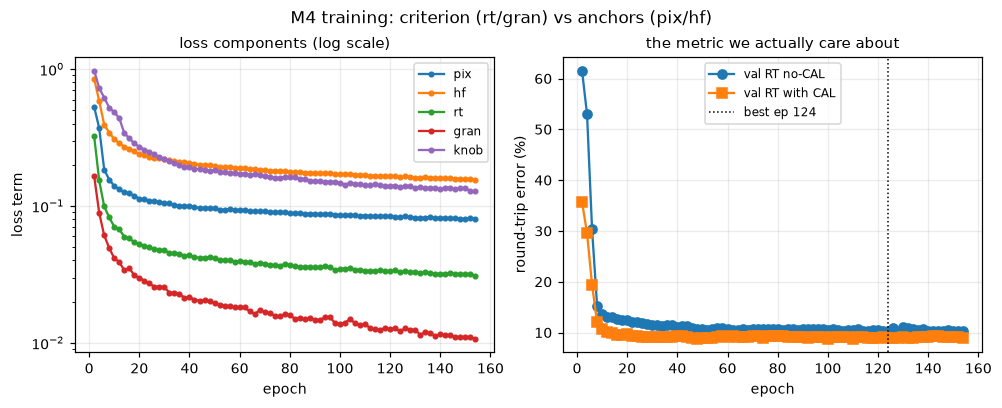

 ep      L    pix     hf   stab     rt   gran   knob  rt_nc  rt_ca
  2 6.2681 0.5298 0.8525 0.0002 0.3234 0.1653 0.9765 0.6158 0.3573
  4 3.6293 0.3713 0.5858 0.0002 0.1537 0.0892 0.7284 0.5294 0.2954
  6 2.4769 0.1844 0.3927 0.0001 0.0992 0.0609 0.6189 0.3030 0.1938
  8 2.0772 0.1558 0.3440 0.0000 0.0825 0.0493 0.5227 0.1532 0.1204
 10 1.8303 0.1400 0.3077 0.0000 0.0707 0.0415 0.4850 0.1366 0.1067
 12 1.7101 0.1326 0.2885 0.0000 0.0673 0.0390 0.4386 0.1304 0.1006
 14 1.4888 0.1262 0.2715 0.0000 0.0598 0.0339 0.3414 0.1310 0.0994
 16 1.4425 0.1237 0.2619 0.0016 0.0579 0.0351 0.3119 0.1274 0.0944
 18 1.3398 0.1190 0.2503 0.0000 0.0543 0.0312 0.2863 0.1246 0.0952
 20 1.2855 0.1130 0.2393 0.0000 0.0529 0.0298 0.2712 0.1247 0.0963
 22 1.2406 0.1123 0.2356 0.0000 0.0508 0.0284 0.2585 0.1213 0.0937
 24 1.2040 0.1093 0.2289 0.0000 0.0500 0.0272 0.2488 0.1210 0.0931
 26 1.1634 0.1080 0.2256 0.0000 0.0482 0.0257 0.2382 0.1188 0.0915
 28 1.1474 0.1073 0.2227 0.0001 0.0478 0.0258 0.2283 0.1168 0.

In [6]:
# ============================================================================
# CELL 4 · training loop (P0 stability + P1 soft-RT + P2 geometry)
#          N-FILE SAFE: everything derives from ROWS/FrameDS/TH_*/COL2COND,
#          so adding data files needs NO edits here -- provided the upstream
#          cells (data -> theta/LIVE-EXTRA -> split -> model) were re-run in
#          the same kernel. New: provenance, loud guards, split visibility.
# ============================================================================
import matplotlib.pyplot as plt
from collections import defaultdict

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10,
                     'savefig.dpi': CFG['DPI'], 'axes.grid': True, 'grid.alpha': 0.25})

# ---- NEW: file inventory (provenance + visibility into the split) --------
_fcol = next((c for c in ROWS.columns
              if ROWS[c].astype(str).str.contains(r'\.h(df)?5\b', case=False, regex=True).any()), None) \
        or next((c for c in ('file', 'filename', 'path', 'src', 'source') if c in ROWS.columns), None)
FILES_USED = (sorted(ROWS[_fcol].astype(str).unique()) if _fcol is not None
              else ['<no file column found in ROWS>'])
NF = len(FILES_USED)
print(f"[m4] data files driving this run ({NF}):")
if _fcol is not None:
    _cnt = ROWS.groupby([_fcol, 'split']).size().unstack(fill_value=0)
    for _f, _r in _cnt.iterrows():
        _parts = '  '.join(f"{s} {int(_r.get(s, 0)):6d}" for s in ('train', 'val', 'test')
                           if s in _r.index)
        print(f"     {os.path.basename(str(_f)):<34} {_parts}")
    _notr  = [os.path.basename(str(f)) for f in _cnt.index if int(_cnt.loc[f].get('train', 0)) == 0]
    _noval = [os.path.basename(str(f)) for f in _cnt.index if int(_cnt.loc[f].get('val', 0)) == 0]
    if _notr:  print(f"[m4][warn] zero TRAIN frames from {_notr} -> their theta is never learned")
    if _noval: print(f"[m4][note] zero VAL frames from {_noval} -> val RT never scores them")

# ---- HF normalizer: mean |laplacian| of real train targets (auto re-samples
#      the CURRENT train rows, so it adapts when files are added) ----------
_fr = ROWS[ROWS.split == 'train']
_fr = _fr.iloc[np.linspace(0, len(_fr) - 1, min(128, len(_fr))).astype(int)]
_hf = 0.0
with torch.no_grad():
    for s in range(0, len(_fr), 32):
        sl = slice(s, min(s + 32, len(_fr)))
        ds = FrameDS(_fr.iloc[sl])
        z = torch.stack([ds[k][1] for k in range(len(ds))]).to(DEVICE)
        _hf += float(lap(z).abs().mean()) * len(ds)
HF_NORM = max(_hf / len(_fr), 1e-6)
print(f"[m4] HF normalizer (mean |lap| of train targets) = {HF_NORM:.4f}")

LIVE_COND_POS = [COL2COND[c] for c in LIVE_COLS]

# ---- NEW: a LIVE column with ~zero sd makes the rt term divide by zero ----
_dead = [c for c in LIVE_COLS if float(TH_SD[c]) <= 1e-8]
assert not _dead, (f"[m4][stop] LIVE_COLS with ~zero sd: {_dead} -- re-run the "
                   "theta / live-vs-extra cell after adding files (the sd-based "
                   "LIVE/EXTRA re-split must be recomputed)")

# ---- F4 fix: knob-consistency loss (the control matrix as a training objective) ----
# Pilot-report F2/F5: the cond vector was a redundant descriptor set, not a control
# panel (D32 sign-flipped despite r=0.87, alpha cross-leak 5x, f_hot dead). This term
# turns the control matrix into a training objective: for a random LIVE cond dim per
# sample, perturb +-KNOB_DELTA sigma, generate both, extract soft theta, and require
# the OWN indicator to move 1:1 in z while the others stay put. Targets every
# frame-level knob at once (alpha / Tmean / f_hot / D32 / nbub) and breaks the
# on-manifold collinearity that left wallTemp redundant.
def knob_loss(model, cond_b, thot_b):
    B = cond_b.size(0)
    n = min(B, CFG.get('KNOB_N', 8))
    if n < 2 or not LIVE_COLS:
        return torch.zeros((), device=cond_b.device)
    idx = torch.randperm(B, device=cond_b.device)[:n]
    cb, tb = cond_b[idx], thot_b[idx]
    dlt = float(CFG.get('KNOB_DELTA', CFG['CONTROL_DELTA']))
    pick_local = torch.randint(0, len(LIVE_COLS), (n,), device=cond_b.device)
    pick_pos = torch.tensor(LIVE_COND_POS, device=cond_b.device, dtype=torch.long)[pick_local]
    cp, cm = cb.clone(), cb.clone()
    rows = torch.arange(n, device=cond_b.device)
    cp[rows, pick_pos] += dlt
    cm[rows, pick_pos] -= dlt
    pp, pm = model(cp), model(cm)                       # 2 extra forwards on a sub-batch
    sp, sm = soft_theta_torch(pp, tb), soft_theta_torch(pm, tb)
    zp = torch.stack([(sp[c] - TH_MU[c]) / TH_SD[c] for c in LIVE_COLS], dim=1)   # (n, L)
    zm = torch.stack([(sm[c] - TH_MU[c]) / TH_SD[c] for c in LIVE_COLS], dim=1)
    dz = (zp - zm) / (2 * dlt)                          # z-response per ask-sigma (n, L)
    own = dz[rows, pick_local]                          # want ~ 1 (1:1 in z)
    leak = dz.clone(); leak[rows, pick_local] = 0       # want ~ 0 (no cross-talk)
    return (own - 1).abs().mean() + leak.abs().mean()

def loss_terms(pred, tgt, cond_b, thot_b):
    """all terms are O(1) at init; LOSS_W sets the priorities (criterion > anchors)."""
    Ls = {}
    Ls['pix'] = F.l1_loss(pred, tgt)
    Ls['hf'] = (lap(pred) - lap(tgt)).abs().mean() / HF_NORM          # P0 anti-blur
    Ls['stab'] = F.relu(pred.abs() - CFG['CLIP_B']).pow(2).mean()     # P0 tail bound
    s = soft_theta_torch(pred, thot_b)                                 # P1 surrogates
    zs = torch.stack([(s[c] - TH_MU[c]) / TH_SD[c] for c in LIVE_COLS], dim=1)
    zt = cond_b[:, LIVE_COND_POS]
    Ls['rt'] = (zs - zt).abs().mean()          # conditioning IS the target (RT!)
    if 'D32' in LIVE_SET:                      # P2: extra weight on geometry
        zgd = (s['D32'] - TH_MU['D32']) / TH_SD['D32']
        Ls['gran'] = (zgd - cond_b[:, COL2COND['D32']]).abs().mean()
    else:
        Ls['gran'] = torch.zeros((), device=pred.device)
    return Ls

ds_train = FrameDS(ROWS[ROWS.split == 'train'])
dl = torch.utils.data.DataLoader(
    ds_train, batch_size=CFG['BATCH'], shuffle=True,
    drop_last=len(ds_train) >= 2 * CFG['BATCH'],
    num_workers=0,                       # Windows/Jupyter-safe; data is in RAM anyway
    pin_memory=(DEVICE.type == 'cuda'))

# ---- NEW: dry-run probe -- a new file that changes the data layout (new
#      descriptor column -> cond dim, or a different frame/channel layout)
#      fails HERE with a clear message, not mid-epoch-1 --------------------
model.eval()
with torch.no_grad():
    _c0, _t0, _h0 = ds_train[0]
    _c0 = _c0[None].float().to(DEVICE); _t0 = _t0[None].float().to(DEVICE)
    _o0 = model(_c0)
    assert tuple(_o0.shape) == tuple(_t0.shape), (
        f"[m4][stop] model output {tuple(_o0.shape)} != target {tuple(_t0.shape)} -- "
        "a new file changed the frame layout (channels/size)? rebuild the target "
        "and model cells in this run")
    if LIVE_COND_POS:
        assert max(LIVE_COND_POS) < _c0.shape[1], (
            f"[m4][stop] LIVE_COND_POS {LIVE_COND_POS} outside cond dim {_c0.shape[1]} "
            "-- COL2COND was rebuilt but the model was NOT (new descriptor column?)")
    if len(COL2COND) != _c0.shape[1]:
        print(f"[m4][warn] COL2COND has {len(COL2COND)} entries but cond vector has "
              f"{_c0.shape[1]} dims -- fine if intentional, else re-check the mapping")
    print(f"[m4] dry-run OK: cond {tuple(_c0.shape)} -> out {tuple(_o0.shape)}, "
          f"{len(ds_train)} train frames, {len(dl)} steps/epoch")
model.train()

opt = torch.optim.AdamW(model.parameters(), lr=CFG['LR'],
                        weight_decay=CFG['WEIGHT_DECAY'])

def lr_at(ep):
    """linear warmup then cosine decay, applied per epoch BEFORE the epoch runs -
    no scheduler.step() ordering hazard at all."""
    w = max(CFG['WARMUP_EPOCHS'], 1)
    if ep <= w:
        return CFG['LR'] * ep / w
    lo = CFG['LR'] / 20.0
    return lo + (CFG['LR'] - lo) * 0.5 * (1 + math.cos(math.pi * (ep - w)
                                                      / max(CFG['EPOCHS'] - w, 1)))

# ---- NEW: tagged checkpoint path (a 3-file run no longer overwrites the
#      2-file best). Flip AUTO_TAG=False if a later cell still looks for
#      the old '{PREFIX}_best.pt' name. ------------------------------------
AUTO_TAG = True
BEST_PATH = os.path.join(OUT_DIR, (f'{PREFIX}_f{NF}files_best.pt' if AUTO_TAG
                                   else f'{PREFIX}_best.pt'))
print(f"[m4] checkpoint path -> {BEST_PATH}")

BEST_W, best_rt, best_ep, hist, bad = None, float('inf'), -1, [], 0
t0, t_step, n_step = time.time(), 0.0, 0

for ep in range(1, CFG['EPOCHS'] + 1):
    for g in opt.param_groups:
        g['lr'] = lr_at(ep)
    model.train()
    run = defaultdict(float)
    nb = 0
    for cond_b, tgt_b, thot_b in dl:
        cond_b = cond_b.to(DEVICE, non_blocking=True)
        tgt_b = tgt_b.to(DEVICE, non_blocking=True)
        thot_b = thot_b.to(DEVICE, non_blocking=True)
        pred = model(cond_b)
        Ls = loss_terms(pred, tgt_b, cond_b, thot_b)
        L = sum(CFG['LOSS_W'][k] * Ls[k] for k in Ls)
        Lk = torch.zeros((), device=pred.device)
        if CFG['LOSS_W'].get('knob', 0.0) > 0:           # F4 fix: knob-consistency
            Lk = knob_loss(model, cond_b, thot_b)
            L = L + CFG['LOSS_W']['knob'] * Lk
        if not torch.isfinite(L):
            raise RuntimeError('non-finite loss - lower LR or raise CLIP_B')
        opt.zero_grad(set_to_none=True)
        L.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CFG['GRAD_CLIP'])   # P0
        opt.step()
        EMA_.update(model)                                                # P0
        nb += 1; n_step += 1
        run['L'] += L.item()
        for k in Ls:
            run[k] += float(Ls[k])
        run['knob'] += float(Lk)
        if ep == 1 and nb == 5:                                           # FIXED units
            t_step = (time.time() - t0) / nb
            print(f"[m4] ~{t_step:.2f} s/step x {len(dl)} steps/ep x {CFG['EPOCHS']} ep "
                  f"-> full run ~{t_step * len(dl) * CFG['EPOCHS'] / 60:.0f} min on {DEVICE} "
                  f"(early stop usually cuts this)")
    if nb == 0:
        continue
    if ep % CFG['EVAL_EVERY'] == 0 or ep == CFG['EPOCHS']:
        rt_nc, rt_ca, cal_q = quick_rt()
        hist.append(dict(ep=ep, **{k: run[k] / nb for k in run},
                         rt_nc=rt_nc, rt_ca=rt_ca))
        mark = '  <- best' if rt_nc < best_rt else ''
        print(f"[m4] ep {ep:3d}/{CFG['EPOCHS']}  "
              f"pix {run['pix']/nb:.3f}  hf {run['hf']/nb:.3f}  rt {run['rt']/nb:.3f}  "
              f"gran {run['gran']/nb:.3f}  knob {run['knob']/nb:.3f}  "
              f"stab {run['stab']/nb:.2e} | "
              f"val RT  nocal {100*rt_nc:5.1f}%   cal {100*rt_ca:5.1f}%{mark}")
        if rt_nc < best_rt:
            best_rt, best_ep, bad = rt_nc, ep, 0
            BEST_W = EMA_.corrected()
            torch.save(dict(ema=BEST_W, raw=model.state_dict(), cfg=CFG, norm=NORM,
                            th_mu=TH_MU, th_sd=TH_SD, live=LIVE_COLS,
                            extra=EXTRA_COLS, epoch=ep,
                            n_files=NF, files=FILES_USED,        # NEW provenance
                            n_train=len(ds_train),
                            cal=dict(a=cal_q.a.tolist(), b=cal_q.b.tolist(),
                                     cols=list(FRAME_COLS))), BEST_PATH)
        else:
            bad += 1
            if bad >= CFG['PATIENCE']:
                print(f"[m4] early stop (no val-RT improvement for {bad} evals)")
                break

assert BEST_W is not None, 'training finished without a single evaluation?'
print(f"[m4] best no-CAL val RT = {100*best_rt:.1f}% at epoch {best_ep}"
      f"  ->  {BEST_PATH}")
print(f"[m4] provenance saved in ckpt: {NF} file(s), {len(ds_train)} train frames; "
      f"archive name for the save cell -> {PREFIX}_ep{best_ep}of{ep}_f{NF}files_<ts>.pt")

# ---- training curves ---------------------------------------------------------
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
for k in ('pix', 'hf', 'rt', 'gran', 'knob'):
    ax[0].plot(h['ep'], h[k], marker='.', label=k)
ax[0].set_yscale('log')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss term')
ax[0].set_title('loss components (log scale)'); ax[0].legend(fontsize=8)
ax[1].plot(h['ep'], 100 * h['rt_nc'], marker='o', label='val RT no-CAL')
ax[1].plot(h['ep'], 100 * h['rt_ca'], marker='s', label='val RT with CAL')
ax[1].axvline(best_ep, color='k', ls=':', lw=1, label=f'best ep {best_ep}')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('round-trip error (%)')
ax[1].set_title('the metric we actually care about'); ax[1].legend(fontsize=8)
fig.suptitle('M4 training: criterion (rt/gran) vs anchors (pix/hf)', fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_curves.png'), bbox_inches='tight')
plt.show()
print(h.round(4).to_string(index=False))
print("[fig] loss components + val RT curves "
      f"(table above) -> {PREFIX}_curves.png")

## 4 · Evaluation: leaderboard, image diagnostics, examples

The leaderboard scores the models where it matters — on **held-out conditions** (test files
18, 22, 100 °C) — and by the **round-trip**, reported both raw and with the affine
correction, with robust statistics: the mean, the median, the 90th percentile and blow-up
counts, because a single exploding frame can drag a mean while saying nothing about the
typical frame. `real(next)` is the floor (3.9 % on test): the error committed by the
simulation's own dynamics when one real frame is asked for the *next* one's descriptor — no
static generator can beat it. Retrieval reaches 7.9 % with near-perfect pixels but 1 885
blow-up frames, and it must keep every training frame in memory.

The image panel keeps the pixel regime honest in its own terms: `pixMSE` (informational — it
disagrees with the round-trip by construction), edge energy (blur below ~0.7, artifacts above
~1.5; real frames sit at 1), the high-frequency fraction (the checkerboard detector) and the
bubble-count ratio. The example grid shows best / median / worst frames with zooms, selected
by the uncorrected round-trip, so the failure modes are visible rather than averaged away.

**This run.** M4: 11.7 % test round-trip (median 10.9, p90 22.4, 8 blow-ups); with the affine
correction, 9.9 %. The error concentrates in the geometry columns — D32 51.5 %, bubble count
34.4 %, α₁ 30.6 % — while the thermal columns are excellent (Tmean 0.3 %, f_hot₁ 0.7 %).
Frames are sharp and artifact-free.

[eval] restored best epoch 124 (no-CAL val RT 10.2%)

[eval] files under evaluation (7):
     Twall_100                          Twall 100.0  val     0  test  2001
     Twall_15                           Twall  15.0  val  2001  test     0
     Twall_18                           Twall  18.0  val     0  test  2001
     Twall_19                           Twall  19.0  val  2001  test     0
     Twall_22                           Twall  22.0  val     0  test  2001
     Twall_23                           Twall  23.0  val  2001  test     0
     Twall_98                           Twall  98.0  val  2001  test     0

=== round-trip leaderboard (mean over live cols, |dtheta|/std_train) ===
                    val   test    med    p90 blow |  alpha  Tmean  f_hot    D32   nbub   (test, %)
-----------------------------------------------------------------------------------------------
real(next)          3.4    3.9    2.7    8.5  134 |    7.7    0.1    1.0    4.7    5.7
M0 mean           136.2  137.4

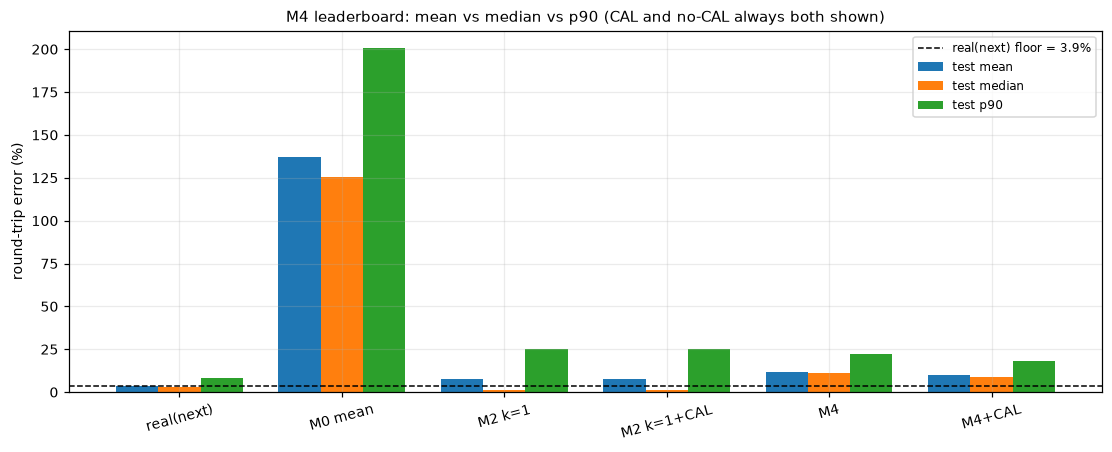

[fig] leaderboard -> M4_leaderboard.png (+ .csv)

[worst live columns, test] (M4 and M4+CAL, %)
    col   M4  M4+CAL
   nbub 34.4    40.6
    D32 51.5    31.5
alpha_1 30.6    22.6
alpha_2 12.7    13.8
alpha_3  7.5     6.6
alpha_4  7.2     6.3
alpha_5  5.6     5.5
f_hot_1  0.7     0.7
Tmean_3  0.3     0.3
Tmean_4  0.3     0.3

[fit] M4  train RT 9.5%   vs   val RT 10.5%   (gap +1.0 pts)
      gap ~ 0 -> healthy interpolation regime; large positive -> overfitting

[per-file RT] does the model favour one condition? (val+test pooled, sorted by mean error)
     file  wallTemp  model    n  mean  median  nngap
Twall_100     100.0     M4 2001 19.16   18.04   1.39
 Twall_98      98.0     M4 2001 18.59   17.74   1.39
 Twall_23      23.0     M4 2001  8.26    5.61   0.10
 Twall_22      22.0     M4 2001  8.14    5.35   0.08
 Twall_19      19.0     M4 2001  7.81    4.77   0.10
 Twall_18      18.0     M4 2001  7.72    4.60   0.08
 Twall_15      15.0     M4 2001  7.47    4.24   0.07
Twall_100     100.

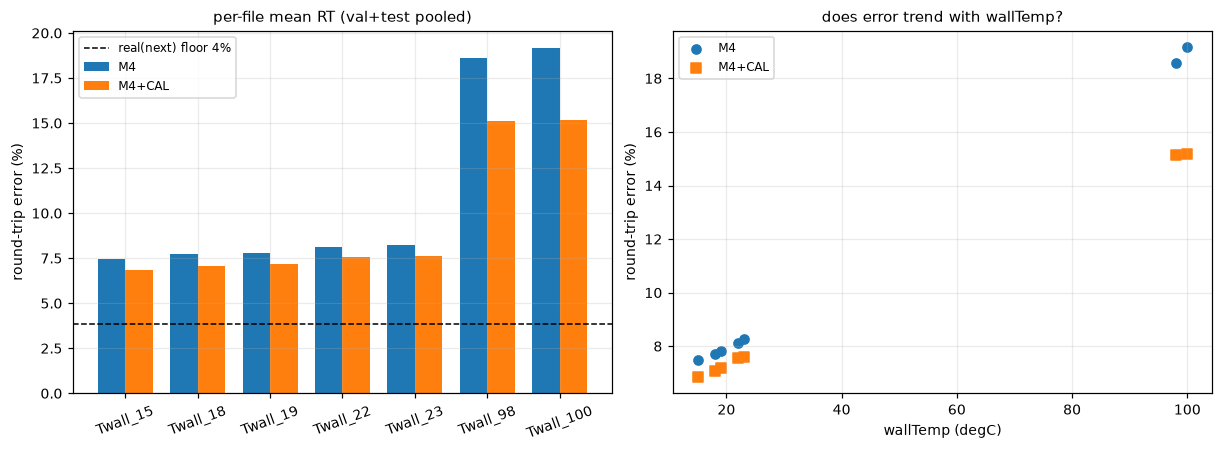

[fig] per-file RT -> M4_perfile.png (+ .csv); nngap = mean distance to the nearest TRAINING cond vector
[read] with >=3 files the right panel is the interpolation check: a middle
       file with LOW error + LOW nngap = real interpolation across Twall.

=== image diagnostics on test (real = 1.0 reference) ===
model       pixMSE_dfun   pixMSE_T  edgeE  HFfrac  nbub
-------------------------------------------------------
M2 k=1            0.006       0.61   0.98    1.00  1.00
M4                0.147       1.41   0.96    1.00  0.83
[read] edgeE/HFfrac/nbub ~ 1 -> sharp, right-sized bubbles. edgeE < 0.7 -> blur;
       edgeE > 1.5 or HFfrac > 2 -> checkerboard/overshoot (M3's disease).
       pixMSE is informational only - it disagrees with the round-trip.


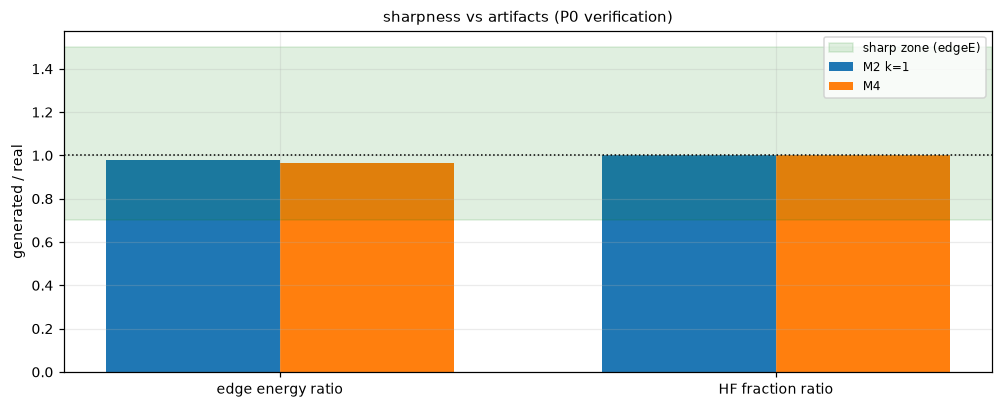

[fig] diagnostics table -> M4_diag.png (numbers above)

[ex] 10 example picks (global best/median/worst + per-file best/median/worst, deduped)
[ex] 10 detailed figures (full + zoom, 2x3 each) -> G:\BoilDesc\src\M4_examples_ep124
[ex] manifest -> G:\BoilDesc\src\M4_examples_ep124\examples_index.csv


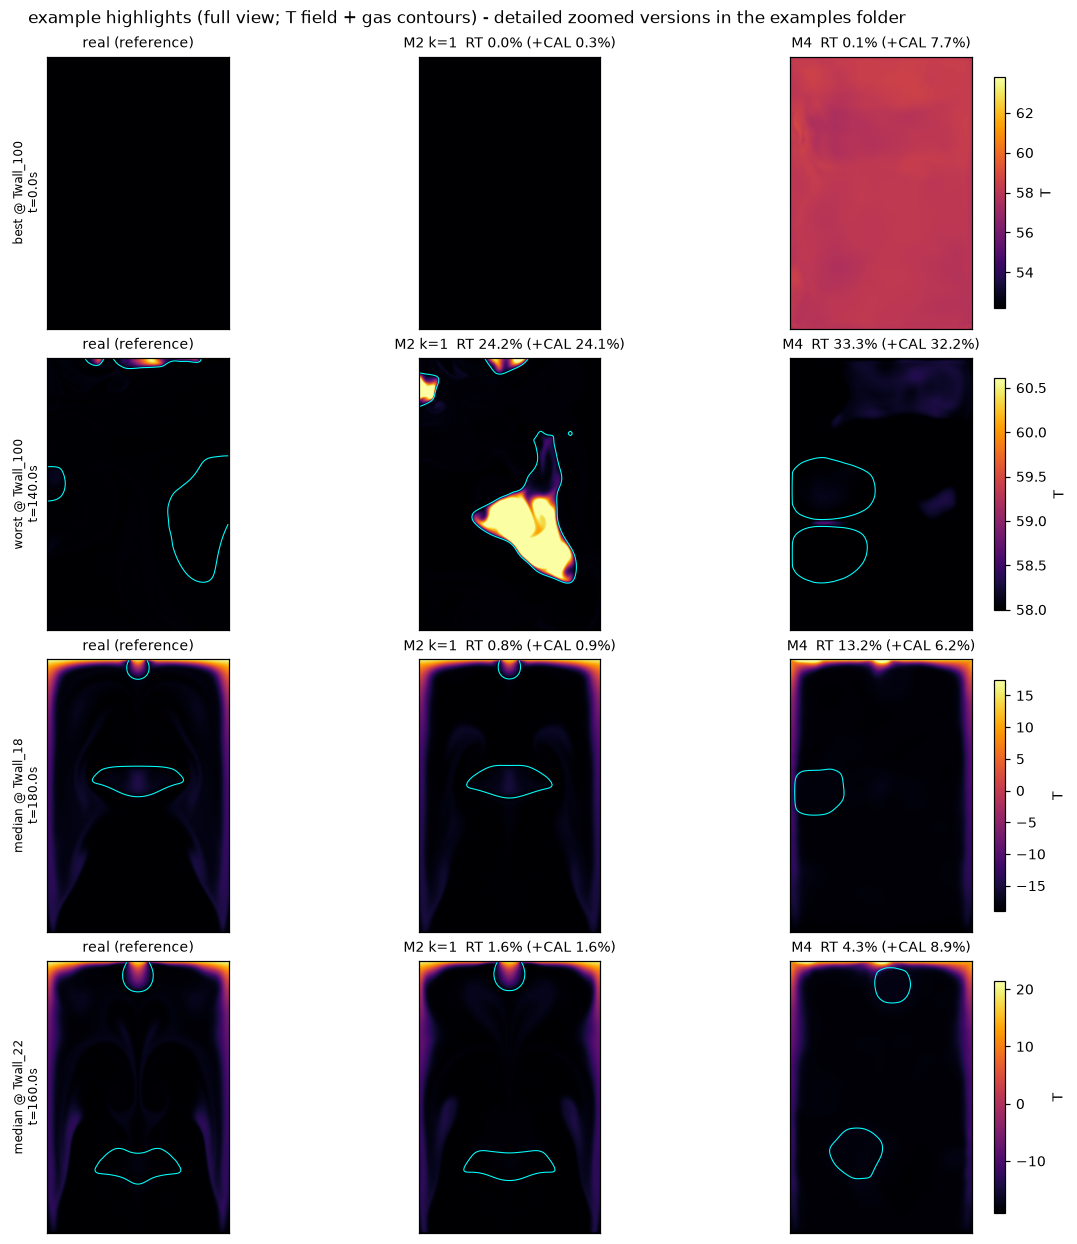

[fig] highlights grid -> M4_examples_highlights.png

[ex] manifest:
 idx          scope   rank      file  wallTemp     t    NNgap real(next)%  M2% M2+CAL%  M4% M4+CAL%                           figure
   1         global   best Twall_100     100.0   0.0 0.209458         0.0  0.0     0.3  0.1     7.7    ex01_best_Twall_100_t0.0s.png
   2         global median  Twall_22      22.0 130.0 0.071589         0.9  1.3     1.5 12.5     7.2 ex02_median_Twall_22_t130.0s.png
   3         global  worst Twall_100     100.0 140.0 1.503306         6.1 24.2    24.1 33.3    32.2 ex03_worst_Twall_100_t140.0s.png
   4 file:Twall_100 median Twall_100     100.0  50.0 1.748008         6.4 21.3    21.5 14.9    17.1 ex04_median_Twall_100_t50.0s.png
   5  file:Twall_18   best  Twall_18      18.0   0.0 0.029973         2.0  0.0     0.3  0.3     6.9     ex05_best_Twall_18_t0.0s.png
   6  file:Twall_18 median  Twall_18      18.0 180.0 0.052603         2.0  0.8     0.9 13.2     6.2 ex06_median_Twall_18_t180.0s.png
 

In [7]:
# ============================================================================
# CELL 5 · full evaluation: leaderboard, per-file analysis, image diagnostics,
#          examples  --  N-FILE EDITION (works for any number of data files)
# ----------------------------------------------------------------------------
#  Pipeline position: after CELL 4 (needs BEST_W / best_ep / best_rt).
#  N-file changes (marked NEW):
#    * M0 mean frame rebuilt from the CURRENT ROWS (SPLIT_POS/tr_mask were
#      stale after the CELL 3 split repair - Twall_98 would have been
#      silently excluded from the mean)
#    * CAL-fit and diagnostics subsamples stratified per file
#    * chunked nearest-neighbour (no NxN distance matrix on GPU)
#    * per-file RT table + NEW figure (bars + error-vs-wallTemp scatter)
#    * examples: global best/median/worst PLUS per-file best/median/worst;
#      every detailed figure saved to a dedicated folder + manifest CSV;
#      a compact highlights grid is shown in the notebook
#    * leaderboard / per-file tables also saved as CSV
# ============================================================================
import os, re
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from collections import defaultdict
try:
    from scipy import ndimage; HAVE_SCI = True
except Exception:
    ndimage, HAVE_SCI = None, False

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 50)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10,
                     'savefig.dpi': CFG['DPI'], 'axes.grid': True, 'grid.alpha': 0.25})

# ---- NEW: upstream contract + per-file stratified subsampling ---------------
for _n in ('CFG', 'DEVICE', 'ROWS', 'DATA', 'COND_Z', 'TH_TRUE', 'FRAME_COLS',
           'LIVE_COLS', 'LIVE_IDX', 'TH_SD', 'NORM', 'H', 'W', 'extract_theta',
           'model', 'OUT_DIR', 'PREFIX', 'BEST_W', 'best_ep', 'best_rt'):
    assert _n in globals(), f"[eval][stop] missing {_n} - run the earlier cells first"
if '_sub_per_file' not in globals():
    def _sub_per_file(rows, n_tot):
        """~n_tot rows with every file represented proportionally."""
        if len(rows) <= n_tot or rows['file'].nunique() <= 1:
            return rows
        parts = []
        for f, g in rows.groupby('file', sort=True):
            k = min(max(1, int(round(n_tot * len(g) / len(rows)))), len(g))
            parts.append(g.iloc[np.linspace(0, len(g) - 1, k).astype(int)])
        return pd.concat(parts)
def _wt(stem):
    try:    return float(DATA[stem]['wallTemp'])
    except Exception: return float('nan')

# ---- restore the best (EMA) weights found during training --------------------
model.load_state_dict(BEST_W)
model.eval()
print(f"[eval] restored best epoch {best_ep} (no-CAL val RT {100*best_rt:.1f}%)")

EVAL_ROWS = ROWS[ROWS.split.isin(['val', 'test'])].copy()
assert len(EVAL_ROWS) > 0, '[eval][stop] no val/test rows - nothing to evaluate'
epos = EVAL_ROWS.index.values                       # row labels, EVAL order
POS_EVAL = {int(r): k for k, r in enumerate(epos)}  # row label -> position in epos
val_m = (EVAL_ROWS.split == 'val').values
test_m = ~val_m
Yt_ev = TH_TRUE[epos]

# ---- NEW: what are we evaluating? -------------------------------------------
print(f"\n[eval] files under evaluation ({EVAL_ROWS['file'].nunique()}):")
for stem, g in EVAL_ROWS.groupby('file', sort=True):
    c = g['split'].value_counts()
    print(f"     {str(stem):<34} Twall {_wt(stem):5.1f}  "
          + '  '.join(f"{s} {int(c.get(s, 0)):5d}" for s in ('val', 'test')))

# ---- M4 predictions over val+test (batched) -----------------------------------
Yh_m4 = np.empty((len(epos), len(FRAME_COLS)), np.float32)
for s in range(0, len(epos), 32):
    sl = slice(s, min(s + 32, len(epos)))
    Yh_m4[sl] = gen_theta(EVAL_ROWS.iloc[sl], ema=False)

# ---- final CAL fits (bigger, NEW: per-file-stratified sample) -----------------
fr = _sub_per_file(ROWS[ROWS.split == 'train'], CFG['FIT_N'])
Yh_fit = gen_theta(fr, ema=False)
CAL_M4 = CAL(FRAME_COLS).fit(TH_TRUE[fr.index.values], Yh_fit)

# ---- baselines ----------------------------------------------------------------
tr_pos = ROWS.index[ROWS.split == 'train'].values
Xtr = torch.from_numpy(COND_Z[tr_pos]).to(DEVICE)
tr_pos_t = torch.from_numpy(tr_pos.astype(np.int64)).to(DEVICE)

def nn_map(pool, exclude_self=False):
    """NEW: chunked nearest-neighbour in cond space (z units) + the gap.
    No NxN matrix on the GPU, so it scales as files are added."""
    pool = np.asarray(pool)
    A = torch.from_numpy(np.asarray(COND_Z[pool])).to(DEVICE)
    pt = torch.from_numpy(pool.astype(np.int64)).to(DEVICE)
    best_d = torch.full((len(pool),), float('inf'), device=DEVICE)
    best_j = torch.zeros(len(pool), dtype=torch.long, device=DEVICE)
    CH = 4096
    for s0 in range(0, len(Xtr), CH):
        D = torch.cdist(A, Xtr[s0:s0 + CH])
        if exclude_self:                       # only meaningful when pool == tr_pos
            D[pt[:, None] == tr_pos_t[None, s0:s0 + CH]] = float('inf')
        dmin, jmin = D.min(1)
        upd = dmin < best_d
        best_d[upd] = dmin[upd]
        best_j[upd] = jmin[upd] + s0
    return tr_pos[best_j.cpu().numpy()], best_d.cpu().numpy()

NN_EVAL, GAP_EVAL = nn_map(epos)

# real(next): the next real frame answers for this one - the physical floor
POS2ROW = {(f, int(p)): r for f, p, r in
           zip(ROWS['file'].values, ROWS['pos'].values, ROWS.index)}
nxt = np.empty(len(ROWS), int)
for stem, grp in ROWS.groupby('file', sort=False):
    o = np.argsort(grp['pos'].values)
    gidx = grp.index.values[o]                 # rows of this file, pos-sorted
    nxt[gidx[:-1]] = gidx[1:]                  # next frame answers
    nxt[gidx[-1]] = gidx[-2] if len(gidx) > 1 else gidx[0]   # last: previous

# NEW: M0 mean frame from the CURRENT ROWS (SPLIT_POS/tr_mask are stale after
#      the split repair - a just-added file would be silently excluded)
tr_rows = ROWS[ROWS.split == 'train']
n_tr = max(len(tr_rows), 1)
acc = np.zeros((2, H, W), np.float64)
for stem, grp in tr_rows.groupby('file', sort=False):
    dd = DATA[stem]
    ps = grp['pos'].values.astype(int)
    acc[0] += np.asarray(dd['dfun'])[ps].astype(np.float64).sum(0)
    acc[1] += np.asarray(dd['T'])[ps].astype(np.float64).sum(0)
mean_d = (acc[0] / n_tr).astype(np.float32)
mean_T = (acc[1] / n_tr).astype(np.float32)
M0_ARR = {}
for th in sorted(EVAL_ROWS['T_HOT'].unique()):
    m0th = extract_theta(mean_d, mean_T, float(th))
    M0_ARR[float(th)] = np.array([m0th[c] for c in FRAME_COLS], np.float32)

PRED = {
    'real(next)': TH_TRUE[nxt[epos]],
    'M0 mean':    np.stack([M0_ARR[float(th)] for th in EVAL_ROWS['T_HOT'].values]),
    'M2 k=1':     TH_TRUE[NN_EVAL],
    'M4':         Yh_m4,
}
NN_TR, _ = nn_map(tr_pos, exclude_self=True)
CAL_M2 = CAL(FRAME_COLS).fit(TH_TRUE[tr_pos], TH_TRUE[NN_TR])
PRED['M2 k=1+CAL'] = CAL_M2.apply(PRED['M2 k=1'])
PRED['M4+CAL'] = CAL_M4.apply(PRED['M4'])

MODELS = ['real(next)', 'M0 mean', 'M2 k=1', 'M2 k=1+CAL', 'M4', 'M4+CAL']
RT = {m: rt_err_frame(PRED[m], Yt_ev) for m in MODELS}

def col_group_err(m, group, mask):
    """mean test error (%) over one indicator group (alpha / Tmean / f_hot / D32 / nbub)."""
    pref = {'alpha': 'alpha_', 'Tmean': 'Tmean_', 'f_hot': 'f_hot_',
            'D32': 'D32', 'nbub': 'nbub'}[group]
    cols = [c for c in LIVE_COLS if c.startswith(pref)]
    if not cols:
        return float('nan')
    idx = [FRAME_COLS.index(c) for c in cols]
    sd = np.array([TH_SD[c] for c in cols])
    return 100 * float(np.mean(np.abs(PRED[m][mask][:, idx] - Yt_ev[mask][:, idx]) / sd))

# ---- leaderboard with robust statistics (P3) ----------------------------------
lead = []
for m in MODELS:
    e_v, e_t = RT[m][val_m], RT[m][test_m]
    med = float(np.median(e_t))
    lead.append(dict(model=m,
                     val=100 * float(e_v.mean()), test=100 * float(e_t.mean()),
                     med=100 * med, p90=100 * float(np.percentile(e_t, 90)),
                     blowups=int((e_t > CFG['BLOWUP_K'] * max(med, 1e-9)).sum()),
                     alpha=col_group_err(m, 'alpha', test_m),
                     Tmean=col_group_err(m, 'Tmean', test_m),
                     f_hot=col_group_err(m, 'f_hot', test_m),
                     D32=col_group_err(m, 'D32', test_m),
                     nbub=col_group_err(m, 'nbub', test_m)))
LEAD = pd.DataFrame(lead).set_index('model')
FLOOR = float(RT['real(next)'][test_m].mean())

print("\n=== round-trip leaderboard (mean over live cols, |dtheta|/std_train) ===")
print(f"{'':16s} {'val':>6s} {'test':>6s} {'med':>6s} {'p90':>6s} {'blow':>4s} |"
      f" {'alpha':>6s} {'Tmean':>6s} {'f_hot':>6s} {'D32':>6s} {'nbub':>6s}   (test, %)")
print("-" * 95)
for m, r in LEAD.iterrows():
    print(f"{m:16s} {r['val']:6.1f} {r['test']:6.1f} {r['med']:6.1f} {r['p90']:6.1f} "
          f"{int(r['blowups']):4d} | {r['alpha']:6.1f} {r['Tmean']:6.1f} "
          f"{r['f_hot']:6.1f} {r['D32']:6.1f} {r['nbub']:6.1f}")
print(f"\n[read] physical floor real(next) = {100*FLOOR:.1f}% (test mean).")
print("[read] rows WITHOUT CAL judge the network itself; CAL rows show what a")
print("       per-column affine still adds. med/p90/blowups expose the")
print("       single-frame blow-ups that means used to hide in M3.")
LEAD.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_leaderboard.csv'))   # NEW

# ---- figure: leaderboard ------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
x = np.arange(len(MODELS))
w = 0.26
for k, key in enumerate(('test', 'med', 'p90')):
    ax.bar(x + (k - 1) * w, LEAD[key], w, label={'test': 'test mean', 'med': 'test median',
                                                 'p90': 'test p90'}[key])
ax.axhline(100 * FLOOR, color='k', ls='--', lw=1,
           label=f'real(next) floor = {100*FLOOR:.1f}%')
ax.set_xticks(x); ax.set_xticklabels(MODELS, rotation=15)
ax.set_ylabel('round-trip error (%)')
ax.set_title('M4 leaderboard: mean vs median vs p90 (CAL and no-CAL always both shown)')
ax.legend(fontsize=8)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_leaderboard.png'))
plt.show()
print("[fig] leaderboard -> %s_leaderboard.png (+ .csv)" % PREFIX)

# ---- worst live columns -------------------------------------------------------
try:
    SD_ARR = np.asarray(SD_F, float).ravel()
    if len(SD_ARR) != len(FRAME_COLS):
        SD_ARR = None
except Exception:
    SD_ARR = None
if SD_ARR is None:                                 # NEW: safe fallback
    SD_ARR = np.array([TH_SD[c] for c in FRAME_COLS], float)
SD_ARR = np.maximum(SD_ARR, 1e-9)

worst = []
for j, c in enumerate(FRAME_COLS):
    if LIVE_IDX[j]:
        worst.append(dict(col=c,
                          M4=100 * float(np.mean(np.abs(PRED['M4'][test_m][:, j]
                                                        - Yt_ev[test_m][:, j]) / SD_ARR[j])),
                          **{'M4+CAL': 100 * float(np.mean(np.abs(PRED['M4+CAL'][test_m][:, j]
                                                          - Yt_ev[test_m][:, j]) / SD_ARR[j]))}))
WC = pd.DataFrame(worst).sort_values('M4+CAL', ascending=False)
print("\n[worst live columns, test] (M4 and M4+CAL, %)")
print(WC.round(1).head(10).to_string(index=False))

# ---- fit-gap (overfit check) --------------------------------------------------
rt_fit = float(rt_err_frame(Yh_fit, TH_TRUE[fr.index.values]).mean())
rt_val = float(RT['M4'][val_m].mean())
print(f"\n[fit] M4  train RT {100*rt_fit:.1f}%   vs   val RT {100*rt_val:.1f}%   "
      f"(gap {100*(rt_val - rt_fit):+.1f} pts)")
print("      gap ~ 0 -> healthy interpolation regime; large positive -> overfitting")

# ---- per-file breakdown (P4) + NEW figure -------------------------------------
pf = []
for stem, grp in EVAL_ROWS.groupby('file', sort=True):
    gi = [POS_EVAL[int(r)] for r in grp.index.values]
    y_t = TH_TRUE[grp.index.values]
    gap = float(np.mean(GAP_EVAL[gi]))            # NEW: conditioning novelty
    for m in ('M4', 'M4+CAL'):
        e = rt_err_frame(PRED[m][gi], y_t)
        pf.append(dict(file=str(stem), wallTemp=_wt(stem), model=m, n=len(grp),
                       mean=100 * float(e.mean()), median=100 * float(np.median(e)),
                       nngap=gap))
PF = pd.DataFrame(pf)
print("\n[per-file RT] does the model favour one condition? (val+test pooled, "
      "sorted by mean error)")
print(PF.sort_values(['model', 'mean'], ascending=[True, False]).round(2).to_string(index=False))
PF.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_perfile.csv'), index=False)   # NEW

has_wt = bool(PF['wallTemp'].notna().all())
order_files = (PF[PF.model == 'M4'].sort_values('wallTemp' if has_wt else 'file')['file']
               .tolist())
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(len(order_files)); w = 0.38
for k, m in enumerate(('M4', 'M4+CAL')):
    vals = [float(PF[(PF.file == f) & (PF.model == m)]['mean'].iloc[0]) for f in order_files]
    axA.bar(x + (k - 0.5) * w, vals, w, label=m)
axA.axhline(100 * FLOOR, color='k', ls='--', lw=1,
            label=f"real(next) floor {100*FLOOR:.0f}%")
axA.set_xticks(x); axA.set_xticklabels(order_files, rotation=20)
axA.set_ylabel('round-trip error (%)')
axA.set_title('per-file mean RT (val+test pooled)')
axA.legend(fontsize=8)
if has_wt and PF[PF.model == 'M4']['wallTemp'].nunique() >= 2:
    for m, mk in (('M4', 'o'), ('M4+CAL', 's')):
        ssub = PF[PF.model == m]
        axB.scatter(ssub['wallTemp'], ssub['mean'], marker=mk, label=m)
    axB.set_xlabel('wallTemp (degC)'); axB.set_ylabel('round-trip error (%)')
    axB.set_title('does error trend with wallTemp?')
    axB.legend(fontsize=8)
else:
    axB.set_axis_off()
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_perfile.png'))
plt.show()
print(f"[fig] per-file RT -> {PREFIX}_perfile.png (+ .csv); "
      "nngap = mean distance to the nearest TRAINING cond vector")
print("[read] with >=3 files the right panel is the interpolation check: a middle")
print("       file with LOW error + LOW nngap = real interpolation across Twall.")

# ---- image diagnostics (P3: sharpness + artifact detector) --------------------
def edge_energy(a):
    return float(np.hypot(ndimage.sobel(a, 0), ndimage.sobel(a, 1)).mean())

def hf_frac(a):
    F_ = np.fft.rfft2(a - a.mean())
    P_ = F_.real ** 2 + F_.imag ** 2
    fy = np.fft.fftfreq(a.shape[0])[:, None]
    fx = np.fft.rfftfreq(a.shape[1])[None, :]
    fr = np.sqrt(fy * fy + fx * fx)
    return float(P_[fr > CFG['HF_CUT']].sum() / max(P_.sum(), 1e-12))

def nbub(d):
    lab, nb = ndimage.label(d > CFG['TAU_DFUN'])
    if nb == 0:
        return 0
    ar = np.bincount(lab.ravel())[1:]
    return int((ar >= CFG['MIN_BUB_PIX']).sum())

# one subsample of test frames serves diagnostics AND example selection
# NEW: stratified per file, so diagnostics are file-balanced as files are added
TST = EVAL_ROWS[test_m].copy()
TST['rt'] = RT['M4'][test_m]
TST['oi'] = np.arange(len(TST))
if len(TST) > CFG['DIAG_N']:
    TST = _sub_per_file(TST, CFG['DIAG_N']).copy()
    TST['oi'] = np.arange(len(TST))
assert len(TST) > 0, '[eval][stop] no test rows for diagnostics/examples'
tpos = TST.index.values
NN_T, _ = nn_map(tpos)
gd_all, gT_all, _ = generate(COND_Z[tpos], TST['T_HOT'].values.astype(np.float32))

if not HAVE_SCI:
    print("\n[diag][skip] scipy.ndimage unavailable - sharpness diagnostics skipped")
    DG = {}
else:
    diag = defaultdict(list)
    for k, i in enumerate(tpos):
        stem = ROWS.iat[i, ROWS.columns.get_loc('file')]
        p = int(ROWS.iat[i, ROWS.columns.get_loc('pos')])
        rd, rT = DATA[stem]['dfun'][p], DATA[stem]['T'][p]
        nrow = ROWS.loc[int(NN_T[k])]
        nd, nT = (DATA[nrow['file']]['dfun'][int(nrow['pos'])],
                  DATA[nrow['file']]['T'][int(nrow['pos'])])
        for m, (fd, fT) in (('M2 k=1', (nd, nT)), ('M4', (gd_all[k], gT_all[k]))):
            diag[f'pixMSE_dfun_{m}'].append(float(np.mean((fd - rd) ** 2)))
            diag[f'pixMSE_T_{m}'].append(float(np.mean((fT - rT) ** 2)))
            diag[f'edgeE_{m}'].append(0.5 * (edge_energy(fd) / max(edge_energy(rd), 1e-9)
                                             + edge_energy(fT) / max(edge_energy(rT), 1e-9)))
            diag[f'HFfrac_{m}'].append(0.5 * (hf_frac(fd) / max(hf_frac(rd), 1e-9)
                                              + hf_frac(fT) / max(hf_frac(rT), 1e-9)))
            diag[f'nbub_{m}'].append(nbub(fd) / max(nbub(rd), 1))
    DG = {k: float(np.median(v)) for k, v in diag.items()}

    print("\n=== image diagnostics on test (real = 1.0 reference) ===")
    print(f"{'model':10s} {'pixMSE_dfun':>12s} {'pixMSE_T':>10s} {'edgeE':>6s} "
          f"{'HFfrac':>7s} {'nbub':>5s}")
    print("-" * 55)
    for m in ('M2 k=1', 'M4'):
        print(f"{m:10s} {DG[f'pixMSE_dfun_{m}']:12.3f} {DG[f'pixMSE_T_{m}']:10.2f} "
              f"{DG[f'edgeE_{m}']:6.2f} {DG[f'HFfrac_{m}']:7.2f} {DG[f'nbub_{m}']:5.2f}")
    print("[read] edgeE/HFfrac/nbub ~ 1 -> sharp, right-sized bubbles. edgeE < 0.7 -> blur;")
    print("       edgeE > 1.5 or HFfrac > 2 -> checkerboard/overshoot (M3's disease).")
    print("       pixMSE is informational only - it disagrees with the round-trip.")

    fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
    xs = np.arange(2)
    w = 0.35
    ax.bar(xs - w / 2, [DG['edgeE_M2 k=1'], DG['HFfrac_M2 k=1']], w, label='M2 k=1')
    ax.bar(xs + w / 2, [DG['edgeE_M4'], DG['HFfrac_M4']], w, label='M4')
    ax.axhspan(0.7, 1.5, color='green', alpha=0.12, label='sharp zone (edgeE)')
    ax.axhline(1.0, color='k', ls=':', lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(['edge energy ratio', 'HF fraction ratio'])
    ax.set_ylabel('generated / real')
    ax.set_title('sharpness vs artifacts (P0 verification)')
    ax.legend(fontsize=8)
    fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_diag.png'))
    plt.show()
    print(f"[fig] diagnostics table -> {PREFIX}_diag.png (numbers above)")

# ---- examples: every file represented ------------------------------------------
# NEW design: picks = global best/median/worst + per-file best/median/worst
# (deduped).  Each pick -> ONE detailed figure (full + zoom, 2x3) saved in a
# dedicated folder; the notebook shows a compact highlights grid only.
ZOOM = int(min(CFG['ZOOM'], H, W))
EXAMPLES_DIR = os.path.join(OUT_DIR, f'{PREFIX}_examples_ep{best_ep}')
os.makedirs(EXAMPLES_DIR, exist_ok=True)
MAX_EX = int(CFG.get('MAX_EXAMPLES', 36))
SHOW_EX = int(CFG.get('SHOW_EXAMPLES', 4))

TST['_file'] = TST['file'].astype(str)
order_g = np.argsort(TST['rt'].values)
pick_entries, _seen = [], set()
def _add(scope, rank, oi):
    if oi in _seen:
        return
    _seen.add(oi)
    pick_entries.append(dict(scope=scope, rank=rank, oi=int(oi)))
for rank, k in (('best', 0), ('median', len(order_g) // 2), ('worst', len(order_g) - 1)):
    _add('global', rank, int(order_g[k]))
for stem, g in TST.groupby('_file', sort=True):
    o = np.argsort(g['rt'].values); n = len(o)
    for rank, k in (('best', 0), ('median', n // 2), ('worst', n - 1)):
        _add(f'file:{stem}', rank, int(g['oi'].values[o[k]]))
if len(pick_entries) > MAX_EX:                     # drop least informative first
    for sc, rk in (('file:', 'median'), ('global', 'median'), ('file:', 'worst')):
        pick_entries = [e for e in pick_entries
                        if not (e['scope'].startswith(sc) and e['rank'] == rk)]
        if len(pick_entries) <= MAX_EX:
            break
print(f"\n[ex] {len(pick_entries)} example picks "
      f"(global best/median/worst + per-file best/median/worst, deduped)")

def ex_data(oi):
    i = int(tpos[oi])
    stem = str(ROWS.iat[i, ROWS.columns.get_loc('file')])
    p = int(ROWS.iat[i, ROWS.columns.get_loc('pos')])
    rd, rT = DATA[stem]['dfun'][p], DATA[stem]['T'][p]
    nrow = ROWS.loc[int(NN_T[oi])]
    nd, nT = (DATA[nrow['file']]['dfun'][int(nrow['pos'])],
              DATA[nrow['file']]['T'][int(nrow['pos'])])
    tval = float(ROWS['t'].iloc[i]) if 't' in ROWS.columns else float('nan')
    return i, stem, tval, rd, rT, nd, nT, gd_all[oi], gT_all[oi]

def zoom_sl(rd):
    """zoom box centred on the largest real bubble (fallback: frame centre)."""
    cy, cx = H / 2, W / 2
    if HAVE_SCI:
        lab, nb = ndimage.label(rd > CFG['TAU_DFUN'])
        if nb:
            sizes = np.bincount(lab.ravel())[1:]
            lid = int(np.argmax(np.where(sizes >= CFG['MIN_BUB_PIX'], sizes, 0))) + 1
            cy, cx = ndimage.center_of_mass(rd > CFG['TAU_DFUN'], lab, lid)
    y0 = int(np.clip(cy - ZOOM / 2, 0, H - ZOOM))
    x0 = int(np.clip(cx - ZOOM / 2, 0, W - ZOOM))
    return (slice(y0, y0 + ZOOM), slice(x0, x0 + ZOOM))

def draw_ex(ax, fd, fT, cut, vmin, vmax, title):
    im = ax.imshow(np.asarray(fT)[cut], cmap='inferno', vmin=vmin, vmax=vmax,
                   aspect='equal')
    try:
        ax.contour(np.asarray(fd)[cut], levels=[CFG['TAU_DFUN']],
                   colors='cyan', linewidths=0.7)
    except Exception:
        pass
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    return im

# detailed figures -> dedicated folder (+ manifest)
manifest = []
for k_, e in enumerate(pick_entries, 1):
    try:
        i, stem, tval, rd, rT, nd, nT, gd, gT = ex_data(e['oi'])
        pe = POS_EVAL[i]
        sl = zoom_sl(rd)
        rt_m2, rt_m2c = 100 * RT['M2 k=1'][pe], 100 * RT['M2 k=1+CAL'][pe]
        rt_m4, rt_m4c = 100 * RT['M4'][pe], 100 * RT['M4+CAL'][pe]
        panels = [('real (reference)', rd, rT, ''),
                  ('M2 k=1', nd, nT, f'RT {rt_m2:.1f}%  (+CAL {rt_m2c:.1f}%)'),
                  ('M4', gd, gT, f'RT {rt_m4:.1f}%  (+CAL {rt_m4c:.1f}%)')]
        vmin, vmax = float(rT.min()), float(rT.max())
        fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4),
                                 constrained_layout=True, squeeze=False)
        for col, (m, fd, fT, sub) in enumerate(panels):
            for row, (tag, cut) in enumerate((('full', slice(None)),
                                              (f'zoom {ZOOM}px', sl))):
                ax = axes[row, col]
                im = draw_ex(ax, fd, fT, cut, vmin, vmax,
                             f"{m}  {sub}" if row == 0 else None)
                if col == 0:
                    ax.set_ylabel(f"{e['rank']}\n{tag}", fontsize=8)
        fig.colorbar(im, ax=axes[:, -1], shrink=0.7, label='T')
        fig.suptitle(f"example {k_:02d}  [{e['scope']} / {e['rank']}]  {stem}  "
                     f"t={tval:.1f}s  (picked by the honest no-CAL RT)", fontsize=10)
        fname = f"ex{k_:02d}_{e['rank']}_{re.sub(r'[^\w\-.]+', '_', stem)}_t{tval:.1f}s.png"
        fig.savefig(os.path.join(EXAMPLES_DIR, fname))
        plt.close(fig)
        manifest.append(dict(idx=k_, scope=e['scope'], rank=e['rank'], file=stem,
                             wallTemp=_wt(stem), t=tval, NNgap=float(GAP_EVAL[pe]),
                             **{'real(next)%': f"{100*RT['real(next)'][pe]:.1f}",
                                'M2%': f"{rt_m2:.1f}", 'M2+CAL%': f"{rt_m2c:.1f}",
                                'M4%': f"{rt_m4:.1f}", 'M4+CAL%': f"{rt_m4c:.1f}",
                                'figure': fname}))
    except Exception as ex:
        print(f"[ex][warn] pick {k_:02d} ({e['scope']} {e['rank']}) failed: {ex}")

MAN = pd.DataFrame(manifest)
MAN.to_csv(os.path.join(EXAMPLES_DIR, 'examples_index.csv'), index=False)
print(f"[ex] {len(MAN)} detailed figures (full + zoom, 2x3 each) -> {EXAMPLES_DIR}")
print(f"[ex] manifest -> {EXAMPLES_DIR}{os.sep}examples_index.csv")

# highlights grid in the notebook: global best + worst, then one median per
# file not already covered (so EVERY file shows up), capped at SHOW_EX
show, shown_oi = [], set()
for e in pick_entries:
    if e['scope'] == 'global' and e['rank'] in ('best', 'worst') and len(show) < SHOW_EX:
        show.append(e); shown_oi.add(e['oi'])
covered = {str(ROWS.iat[int(tpos[e['oi']]), ROWS.columns.get_loc('file')]) for e in show}
for stem in sorted(TST['_file'].unique()):
    if stem not in covered and len(show) < SHOW_EX:
        cand = next((e for e in pick_entries
                     if e['scope'] == f'file:{stem}' and e['rank'] == 'median'), None) \
            or next((e for e in pick_entries if e['scope'] == f'file:{stem}'), None)
        if cand is not None and cand['oi'] not in shown_oi:
            show.append(cand); shown_oi.add(cand['oi'])
            covered.add(stem)
missing = [f for f in sorted(TST['_file'].unique()) if f not in covered]
if missing:
    print(f"[ex][note] not shown inline (see the folder): {missing}")

if show:
    nrow = len(show)
    fig, axes = plt.subplots(nrow, 3, figsize=(11, 2.6 * nrow + 0.8),
                             constrained_layout=True, squeeze=False)
    for r_, e in enumerate(show):
        i, stem, tval, rd, rT, nd, nT, gd, gT = ex_data(e['oi'])
        pe = POS_EVAL[i]
        vmin, vmax = float(rT.min()), float(rT.max())
        panels = [('real (reference)', rd, rT, ''),
                  ('M2 k=1', nd, nT, f"RT {100*RT['M2 k=1'][pe]:.1f}% "
                                     f"(+CAL {100*RT['M2 k=1+CAL'][pe]:.1f}%)"),
                  ('M4', gd, gT, f"RT {100*RT['M4'][pe]:.1f}% "
                                 f"(+CAL {100*RT['M4+CAL'][pe]:.1f}%)")]
        for c_, (m, fd, fT, sub) in enumerate(panels):
            ax = axes[r_, c_]
            im = draw_ex(ax, fd, fT, slice(None), vmin, vmax, (f"{m}  {sub}" if sub else m))
            if c_ == 0:
                ax.set_ylabel(f"{e['rank']} @ {stem}\nt={tval:.1f}s", fontsize=8)
        fig.colorbar(im, ax=axes[r_, :], shrink=0.85, pad=0.02, label='T')
    fig.suptitle('example highlights (full view; T field + gas contours) - '
                 'detailed zoomed versions in the examples folder', fontsize=11)
    fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_examples_highlights.png'))
    plt.show()
    print("[fig] highlights grid -> %s_examples_highlights.png" % PREFIX)

print('\n[ex] manifest:')
print(MAN.to_string(index=False))
print("\n[read] CAL does not change frames - +CAL numbers re-report the SAME M4 image's")
print("       extracted theta through a per-column affine (that is why the example")
print("       figures show one M4 column with both RT numbers).")
print("[read] picks are by the honest no-CAL RT; NNgap = distance to the nearest")
print("       training cond vector (high NNgap + decent RT = honest extrapolation).")

## 5 · Diagnostics: knobs, stability, support, verdicts

Averages say *that* a model fails; these eight tests say *why*. **Stability** — field extrema
stay within 4.4 σ, and the blow-up list holds 8 frames, all in the vigorous-boiling condition
around t ≈ 192 s. **CAL magnitude** — the affine moves the test round-trip by 1.7 points
(11.7 → 9.9 %) and its gains sit at ≈ 1 for the thermal columns: the correction is residual;
the network itself carries the round-trip. **D32 response** — slope 1.15, r = 0.86: the right
correlation, still amplified. **The control matrix** — perturb each conditioning column by
± 0.25 σ and measure what comes back — is the knob autopsy: α gains of 1–2.7 with cross-leak
≈ 1 (steerable but overshooting), Tmean 0.26–0.45, f_hot 0.25, bubble count 1.21, D32
**− 0.45** (the sign is wrong), and a *dead* wall-temperature knob (gain 0.01) whose sign
nevertheless matches the data (+0.94 °C/°C measured across files). Steering, in short, must
go through the thirteen descriptor columns, not through the wall temperature.
**Retrieval-gap analysis** — round-trip error versus distance to the nearest training
condition: Spearman + 0.69 (retrieval: + 0.94), i.e. still data-limited; adding files remains
the highest-leverage fix. **Drift, coverage and the verdict checklist** close the cell with
data-driven next steps.

=== 1) stability (P0) ===
  max |z| of generated fields : 4.41 sigma  (hard clamp at 6; soft penalty above 4)
  blow-up frames (test)       : 8  (RT > 5 x median = 55%)
     Twall_100            192.0s   RT 81%
     Twall_100            192.1s   RT 86%
     Twall_100            192.2s   RT 91%
     Twall_100            192.3s   RT 99%
     Twall_100            192.4s   RT 93%
 model  pixMSE_T  edgeE  HFfrac
M2 k=1      0.61   0.98     1.0
    M4      1.41   0.96     1.0

=== 2) CAL magnitude (P1) - how much the affine still corrects ===
  mean |gain-1| = 0.071   mean |offset| = 0.076 sigma
  test RT: no-CAL 11.7%  ->  CAL 9.9%   (CAL adds 1.7 pts)
    col  gain  offset_sd
alpha_1 0.800      0.240
alpha_2 0.903      0.053
alpha_3 0.957     -0.000
alpha_4 0.949      0.008
alpha_5 0.957      0.003
Tmean_1 1.000      0.001
Tmean_2 1.000      0.001
Tmean_3 1.000      0.000
Tmean_4 1.000      0.000
Tmean_5 1.000     -0.000
f_hot_1 0.999     -0.001
    D32 0.762      0.628
   nbub 1.245      

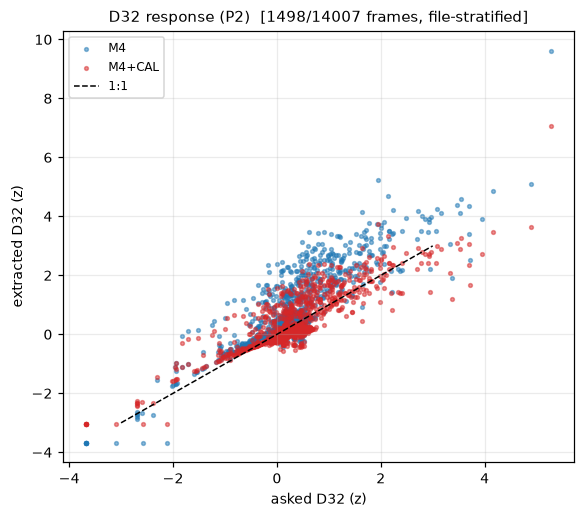


=== 4) control matrix (response of theta_hat to +-0.25 sigma asks) ===
    knob type  gain  maxleak
 alpha_1 live  2.71     1.20
 alpha_2 live  2.17     1.21
 alpha_3 live  2.69     0.89
 alpha_4 live  1.58     1.44
 alpha_5 live  0.96     0.63
 Tmean_1 live  0.43     0.22
 Tmean_2 live  0.26     1.43
 Tmean_3 live  0.45     1.98
 Tmean_4 live  0.40     1.48
 Tmean_5 live  0.32     1.48
 f_hot_1 live  0.25     1.21
     D32 live -0.45     2.41
    nbub live  1.21     1.51
wallTemp case  0.01     2.74
  [read] gain ~ 1 -> knob directly controllable; leak >> 0.3 -> cross-talk;
         for case scalars (e.g. wallTemp) gain = the Tmean heating response.
  [sign] real dTmean/dTwall = +0.940 degC/degC across 15 files (Twall [np.float64(10.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(26.0), np.float64(75.0), np.float64(98.0), np.float64(100.0), np.float64(107.0

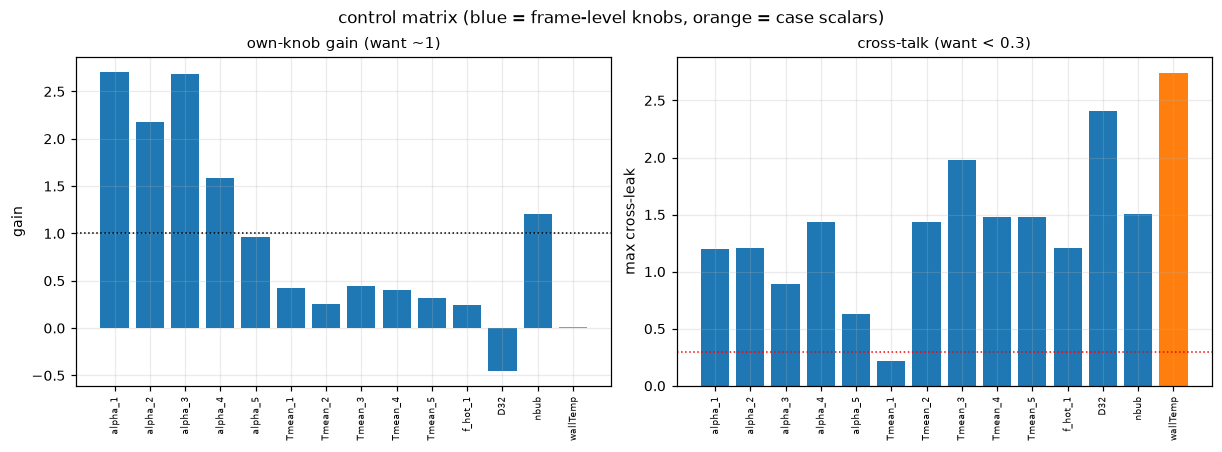


=== 5) retrieval-gap analysis (val+test) ===
                bin     n  M2 k=1   M4  M4+CAL
 <0.5 (0.0-0.5 sig) 10124     1.1  7.9     7.3
0.5-1 (0.5-1.0 sig)   760     9.8 17.2    13.6
1-1.5 (1.0-1.5 sig)  1656    19.5 19.8    14.9
1.5-2 (1.5-2.0 sig)  1054    27.2 19.2    15.4
  2-3 (2.0-3.0 sig)   380    37.9 20.7    19.4
  3-4 (3.0-3.9 sig)    27    57.9 21.2    23.2
   >4 (4.1-4.4 sig)     6    74.6 23.8    33.0
  Spearman(err, NN z-gap):  M2 k=1 +0.94   M4 +0.69   M4+CAL +0.73
  [read] flat M4 bars / rho ~ 0 -> sparsity closed (parametric interpolation
         works); rising bars -> M4 is still gap-limited -> more data (files).
         with >=3 files expect most frames in the <1 sigma bin - that IS the
         sparsity win; watch the 1.5+ bins for the honest extrapolators.


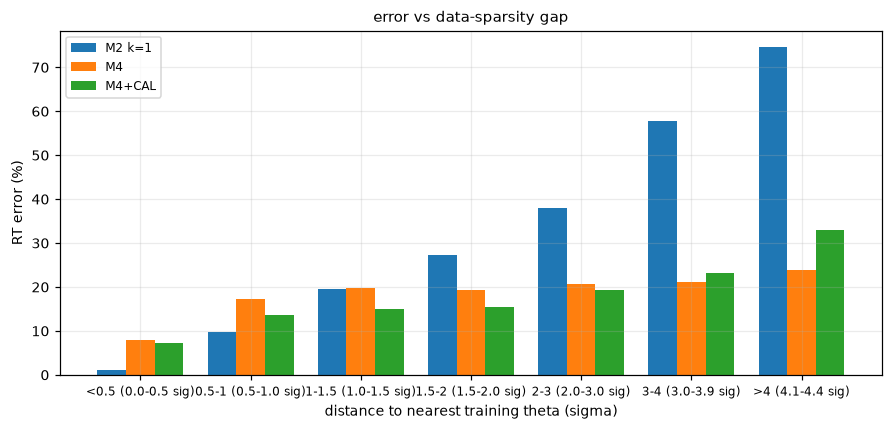

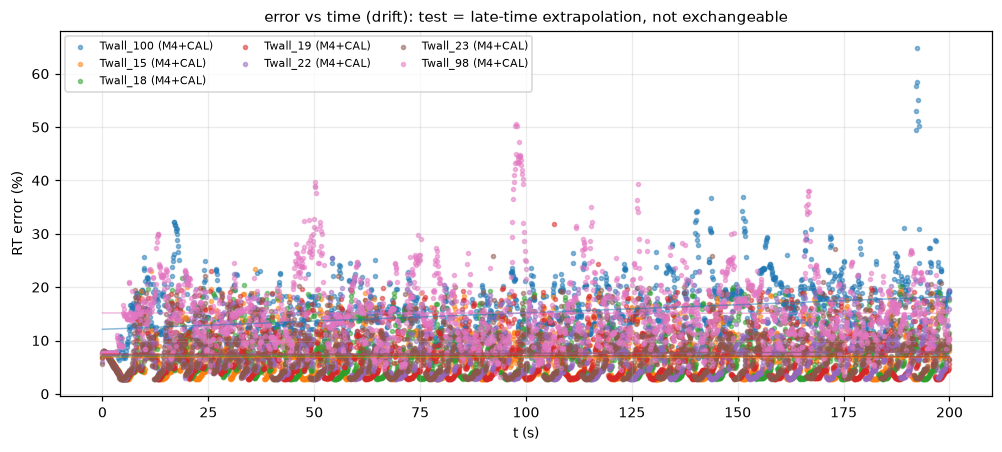

=== 6) error vs time (M4+CAL) ===
     file  wallTemp    n  pts_per_span
Twall_100     100.0 2001           6.1
 Twall_15      15.0 2001          -0.0
 Twall_18      18.0 2001          -0.1
 Twall_19      19.0 2001          -0.5
 Twall_22      22.0 2001           0.6
 Twall_23      23.0 2001           0.6
 Twall_98      98.0 2001          -0.1
  median drift = -0.0 pts per time-span (|trend| large -> regime drift inside the file)
  [read] compare pts_per_span ACROSS files: does late-time degradation
         scale with Twall? (that pattern is what M4 must learn next)

=== 7) coverage (P4) ===
  files            : 15  ->  ['Twall_10', 'Twall_100', 'Twall_107', 'Twall_13', 'Twall_14', 'Twall_15', 'Twall_17', 'Twall_18', 'Twall_19', 'Twall_21', 'Twall_22', 'Twall_23', 'Twall_26', 'Twall_75', 'Twall_98']
  wallTemp values  : [10.0, 13.0, 14.0, 15.0, 17.0, 18.0, 19.0, 21.0, 22.0, 23.0, 26.0, 75.0, 98.0, 100.0, 107.0]  (varies -> it IS a conditioning knob now)
  live columns     : 13/17  dea

In [8]:
# ============================================================================
# CELL 6 · diagnostic tests, verdicts, recommendations, artifact save
#          N-FILE EDITION (works for any number of data files)
# ----------------------------------------------------------------------------
#  Pipeline position: after CELL 5 (needs RT / PRED / LEAD / GAP_EVAL / DG ...).
#  NEW: defensive upstream globals, NaN-safe wallTemp coverage, wallTemp SIGN
#  cross-check vs the data, xval auto-detect (multiple hold-out files), finer
#  gap bins, scipy guards, per-file tables + CSVs, dynamic artifact listing.
# ============================================================================
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

if 'sps' not in globals():
    try:    import scipy.stats as sps
    except Exception: sps = None

def _g(name, default=None):
    return globals().get(name, default)
def _fmt(v, p='{:.2f}'):
    try:    return p.format(float(v)) if np.isfinite(v) else 'n/a'
    except Exception: return 'n/a'
def _corr(x, y):
    if sps is None: return float('nan')
    try:
        r = sps.pearsonr(np.asarray(x, float), np.asarray(y, float))
        return float(r.statistic if hasattr(r, 'statistic') else r[0])
    except Exception: return float('nan')
def _spear(x, y):
    if sps is None or len(x) < 4: return float('nan')
    try:
        r = sps.spearmanr(np.asarray(x, float), np.asarray(y, float))
        return float(r.statistic if hasattr(r, 'statistic') else r[0])
    except Exception: return float('nan')
if '_wt' not in globals():
    def _wt(stem):
        try:    return float(DATA[stem]['wallTemp'])
        except Exception: return float('nan')

# ---- NEW: defensive upstream globals (stale/missing -> fallback, no crash) ----
_tr = ROWS[ROWS.split == 'train']
if 'SD_F' in globals() and len(np.asarray(SD_F).ravel()) == len(FRAME_COLS):
    _SDARR = np.maximum(np.asarray(SD_F, float).ravel(), 1e-9)
else:
    _SDARR = np.maximum(np.array([TH_SD[c] for c in FRAME_COLS], float), 1e-9)
    print("[c6][note] SD_F missing/stale -> per-column TH_SD used")
if 'MU_F' in globals() and len(np.asarray(MU_F).ravel()) == len(FRAME_COLS):
    _MUARR = np.asarray(MU_F, float).ravel()
else:
    _MUARR = np.array([TH_MU[c] for c in FRAME_COLS], float)
    print("[c6][note] MU_F missing/stale -> per-column TH_MU used")
DEAD_COLS      = list(_g('DEAD_COLS') or [])
WTEMP_COND_COL = _g('WTEMP_COND_COL')
XVSTEM         = _g('XVSTEM')
COND_COLS      = _g('COND_COLS')
if COND_COLS is None:
    COND_COLS = [c for c, _ in sorted(COL2COND.items(), key=lambda kv: kv[1])]
    print("[c6][note] COND_COLS missing -> derived from COL2COND")
t_hot_of_cond  = _g('t_hot_of_cond')
if t_hot_of_cond is None:
    _thm = float(_tr['T_HOT'].mean())
    t_hot_of_cond = lambda a: _thm
    print(f"[c6][note] t_hot_of_cond missing -> constant {_thm:.2f} "
          "(f_hot responses will be flat)")
NF    = int(ROWS['file'].astype(str).nunique())
Yt_pool, gaps_pool = Yt_ev, GAP_EVAL.astype(np.float64)

# ---------------- 1) stability (P0) -------------------------------------------
e_t = RT['M4'][test_m]
med_t = float(np.median(e_t))
blow = np.where(e_t > CFG['BLOWUP_K'] * max(med_t, 1e-9))[0]
has_t = 't' in EVAL_ROWS.columns
blow_list = []
for b in blow:
    row = EVAL_ROWS.iloc[np.where(test_m)[0][b]]
    tl = f"{row['t']:.1f}s" if has_t else f"pos {int(row['pos'])}"
    blow_list.append((row['file'], tl, 100 * e_t[b]))
print("=== 1) stability (P0) ===")
print(f"  max |z| of generated fields : {ZMAX[0]:.2f} sigma  (hard clamp at "
      f"{CFG['CLIP_INF']:.0f}; soft penalty above {CFG['CLIP_B']:.0f})")
print(f"  blow-up frames (test)       : {len(blow)}  (RT > {CFG['BLOWUP_K']:g} x median"
      f" = {100*CFG['BLOWUP_K']*med_t:.0f}%)")
for f, t, e in blow_list[:5]:
    print(f"     {str(f):16s} {t:>10s}   RT {e:.0f}%")
EDGE_M4 = float(DG.get('edgeE_M4', float('nan'))) if isinstance(DG, dict) else float('nan')
HFFR_M4 = float(DG.get('HFfrac_M4', float('nan'))) if isinstance(DG, dict) else float('nan')
if isinstance(DG, dict) and 'pixMSE_T_M2 k=1' in DG:
    stab_tab = pd.DataFrame([dict(model=m, pixMSE_T=DG[f'pixMSE_T_{m}'],
                                  edgeE=DG[f'edgeE_{m}'], HFfrac=DG[f'HFfrac_{m}'])
                             for m in ('M2 k=1', 'M4')])
    print(stab_tab.round(2).to_string(index=False))
else:
    print("  [image diagnostics not available - scipy.ndimage was missing in CELL 5]")
P0_STABLE = (ZMAX[0] <= CFG['CLIP_INF'] + 1e-3) and (len(blow) == 0)
P0_SHARP = (0.7 <= EDGE_M4 <= 1.5) and (HFFR_M4 <= 2.0) if np.isfinite(EDGE_M4) else None

# ---------------- 2) CAL magnitude (P1) ----------------------------------------
cal_delta = 100 * (float(e_t.mean()) - float(RT['M4+CAL'][test_m].mean()))
live_j = [j for j in range(len(FRAME_COLS)) if LIVE_IDX[j]]
CAL_TAB = pd.DataFrame([dict(col=FRAME_COLS[j], gain=CAL_M4.a[j],
                             offset_sd=CAL_M4.b[j] / _SDARR[j]) for j in live_j])
print("\n=== 2) CAL magnitude (P1) - how much the affine still corrects ===")
print(f"  mean |gain-1| = {CAL_TAB['gain'].sub(1).abs().mean():.3f}   "
      f"mean |offset| = {CAL_TAB['offset_sd'].abs().mean():.3f} sigma")
print(f"  test RT: no-CAL {100*float(e_t.mean()):.1f}%  ->  CAL "
      f"{100*float(RT['M4+CAL'][test_m].mean()):.1f}%   (CAL adds {cal_delta:.1f} pts)")
print(CAL_TAB.round(3).to_string(index=False))
CAL_TAB.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_cal.csv'), index=False)      # NEW
print("  [read] P1 succeeded when CAL adds only a little: the net itself carries RT.")
P1_NET = (100 * float(e_t.mean())) <= 2 * 100 * FLOOR
P1_CAL_SMALL = cal_delta < 2.0

# ---------------- 3) D32 response (P2) -----------------------------------------
d32_j = FRAME_COLS.index('D32')
y_true = TH_TRUE[epos][:, d32_j]
d32_rows = []
for m in ('M4', 'M4+CAL'):
    yh = PRED[m][:, d32_j]
    if np.std(yh) > 1e-9 and np.std(y_true) > 1e-9:
        slope = float(np.polyfit(y_true, yh, 1)[0])
        r = _corr(y_true, yh)
    else:
        slope, r = float('nan'), float('nan')
    bias = 100 * float(np.mean(yh - y_true) / max(np.mean(y_true), 1e-9))
    d32_rows.append(dict(model=m, slope=slope, r=r, bias_pct=bias))
D32_TAB = pd.DataFrame(d32_rows)
print("\n=== 3) D32 response (P2) ===")
print(D32_TAB.round(2).to_string(index=False))
D32_TAB.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_d32.csv'), index=False)      # NEW
print("  [read] slope<1 geometry shrinks / slope>1 exaggerates; both mean the D32")
print("         response is underfit. slope~1, r high, |bias| small -> knob earned.")
_sc = EVAL_ROWS.copy(); _sc['k'] = np.arange(len(_sc))                        # NEW:
if '_sub_per_file' in globals():                                              # file-stratified
    _sc = _sub_per_file(_sc, 1500)                                            # subsample
_kk = _sc['k'].values.astype(int)
fig, ax = plt.subplots(figsize=(5.2, 4.6), constrained_layout=True)
zx = (y_true[_kk] - TH_MU['D32']) / TH_SD['D32']
for m, col in (('M4', 'tab:blue'), ('M4+CAL', 'tab:red')):
    zy = (PRED[m][_kk, d32_j] - TH_MU['D32']) / TH_SD['D32']
    ax.scatter(zx, zy, s=6, alpha=0.5, color=col, label=m)
ax.plot([-3, 3], [-3, 3], 'k--', lw=1, label='1:1')
ax.set_xlabel('asked D32 (z)'); ax.set_ylabel('extracted D32 (z)')
ax.set_title(f'D32 response (P2)  [{len(_kk)}/{len(epos)} frames, file-stratified]')
ax.legend(fontsize=8)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_d32.png'))
plt.show()
_slope0, _r0 = float(D32_TAB['slope'].iloc[0]), float(D32_TAB['r'].iloc[0])
D32_OK = bool(np.isfinite(_slope0) and 0.85 <= _slope0 <= 1.15
              and np.isfinite(_r0) and _r0 >= 0.7)

# ---------------- 4) control matrix (P2 + P4) ----------------------------------
base = COND_Z[epos[val_m]].mean(0)
DELTA = CFG['CONTROL_DELTA']
tmean_idx = [FRAME_COLS.index(c) for c in FRAME_COLS if c.startswith('Tmean')]
live_pos = list(np.where(LIVE_IDX)[0])               # live columns' positions
tmean_live = [live_pos.index(j) for j in tmean_idx if j in live_pos]
ctrl_rows = []
for j, cname in enumerate(COND_COLS):
    asks = np.stack([base, base.copy(), base.copy()]).astype(np.float32)
    asks[1, j] += DELTA
    asks[2, j] -= DELTA
    th = np.array([t_hot_of_cond(a) for a in asks], np.float32)
    d, T, _ = generate(asks, th)
    Y = theta_of_frames(d, T, th)
    Z = (Y - _MUARR) / _SDARR                                # (3, n_cols) z-space
    dz = (Z[1] - Z[2]) / (2 * DELTA)                         # z-response per ask-sigma
    dz_live = dz[live_pos]
    if cname in LIVE_SET:
        jj = live_pos.index(FRAME_COLS.index(cname))
        own = float(dz_live[jj])
        leak = float(np.max(np.abs(np.delete(dz_live, jj))))
    else:   # case scalar (e.g. wallTemp): heating response = Tmean, leak = rest
        own = float(np.mean(dz_live[tmean_live])) if tmean_live else 0.0
        rest = np.delete(dz_live, tmean_live) if tmean_live else dz_live
        leak = float(np.max(np.abs(rest))) if len(rest) else 0.0
    ctrl_rows.append(dict(knob=cname, type='live' if cname in LIVE_SET else 'case',
                          gain=own, maxleak=leak))
CTRL = pd.DataFrame(ctrl_rows)
CTRL.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_control.csv'), index=False)     # NEW
print("\n=== 4) control matrix (response of theta_hat to +-%.2f sigma asks) ===" % DELTA)
print(CTRL.round(2).to_string(index=False))
print("  [read] gain ~ 1 -> knob directly controllable; leak >> 0.3 -> cross-talk;")
print("         for case scalars (e.g. wallTemp) gain = the Tmean heating response.")

# ---- NEW: wallTemp SIGN cross-check (data slope vs control gain) --------------
wt_files = [(str(s), float(DATA[s]['wallTemp'])) for s in sorted(DATA.keys())
            if np.isfinite(float(DATA[s]['wallTemp']))]
slope_wt, WT_SIGN_OK = float('nan'), None
tm_cols = [FRAME_COLS.index(c) for c in FRAME_COLS if c.startswith('Tmean_')] \
          or [FRAME_COLS.index(c) for c in FRAME_COLS if c.startswith('Tmean')]
if len(wt_files) >= 2 and tm_cols:
    xs_w = np.array([w for _, w in wt_files])
    ys_w = [float(np.mean(TH_TRUE[ROWS.index[ROWS['file'].astype(str) == stem]][:, tm_cols]))
            for stem, _ in wt_files]
    if np.ptp(xs_w) > 0:
        slope_wt = float(np.polyfit(xs_w, ys_w, 1)[0])
        print(f"  [sign] real dTmean/dTwall = {slope_wt:+.3f} degC/degC across "
              f"{len(wt_files)} files (Twall {sorted(xs_w)})")
if np.isfinite(slope_wt) and WTEMP_COND_COL is not None \
        and WTEMP_COND_COL in set(CTRL['knob']):
    g_wt = float(CTRL.loc[CTRL['knob'] == WTEMP_COND_COL, 'gain'].iloc[0])
    if g_wt != 0.0:
        WT_SIGN_OK = (g_wt * slope_wt) > 0
        print(f"  [sign] model wallTemp gain = {g_wt:+.2f}  ->  "
              + ("SIGN MATCHES the data" if WT_SIGN_OK else
                 "SIGN DISAGREES with the data (conditioning reversed!)"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
xs = np.arange(len(CTRL))
colsb = ['tab:blue' if t == 'live' else 'tab:orange' for t in CTRL['type']]
ax[0].bar(xs, CTRL['gain'], color=colsb)
ax[0].axhline(1.0, color='k', ls=':', lw=1)
ax[0].set_xticks(xs); ax[0].set_xticklabels(CTRL['knob'], rotation=90, fontsize=6)
ax[0].set_ylabel('gain'); ax[0].set_title('own-knob gain (want ~1)')
ax[1].bar(xs, CTRL['maxleak'], color=colsb)
ax[1].axhline(0.3, color='r', ls=':', lw=1)
ax[1].set_xticks(xs); ax[1].set_xticklabels(CTRL['knob'], rotation=90, fontsize=6)
ax[1].set_ylabel('max cross-leak'); ax[1].set_title('cross-talk (want < 0.3)')
fig.suptitle('control matrix (blue = frame-level knobs, orange = case scalars)', fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_control.png'))
plt.show()
_gain_d32 = float(CTRL.loc[CTRL['knob'] == 'D32', 'gain'].iloc[0]) \
    if 'D32' in set(CTRL['knob']) else 0.0
_gain_nbub = float(CTRL.loc[CTRL['knob'] == 'nbub', 'gain'].iloc[0]) \
    if 'nbub' in set(CTRL['knob']) else float('nan')
_alpha_rows = CTRL.loc[CTRL['knob'].str.startswith('alpha'), 'maxleak']       # NEW guard
_alpha_leak = float(_alpha_rows.max()) if len(_alpha_rows) else float('nan')
CTRL_OK = (_gain_d32 >= 0.5) and (not len(_alpha_rows) or _alpha_leak < 0.3)

# ---------------- 5) retrieval-gap analysis (P4) -------------------------------
EDGES = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]     # NEW: finer low end - with >=3 files
bins = np.digitize(gaps_pool, EDGES)       # most gaps drop below 1 sigma
def _blabel(b):
    if b == 0:         return f"<{EDGES[0]:g}"
    if b < len(EDGES): return f"{EDGES[b-1]:g}-{EDGES[b]:g}"
    return f">{EDGES[-1]:g}"
gap_rows = []
for b in sorted(set(bins)):
    msk = bins == b
    if msk.sum() == 0:
        continue
    row = dict(bin=f"{_blabel(b)} ({gaps_pool[msk].min():.1f}-{gaps_pool[msk].max():.1f} sig)",
               n=int(msk.sum()))
    for mm in ('M2 k=1', 'M4', 'M4+CAL'):
        row[mm] = 100 * float(np.mean(RT[mm][msk]))
    gap_rows.append(row)
GAP_TAB = pd.DataFrame(gap_rows)
rhos = {mm: _spear(gaps_pool, RT[mm]) for mm in ('M2 k=1', 'M4', 'M4+CAL')}
print("\n=== 5) retrieval-gap analysis (val+test) ===")
print(GAP_TAB.round(1).to_string(index=False) if len(GAP_TAB) else "  (no gap rows)")
print("  Spearman(err, NN z-gap):  "
      + "   ".join(f"{k} {_fmt(v, '{:+.2f}')}" for k, v in rhos.items()))
GAP_TAB.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_gap.csv'), index=False)      # NEW
print("  [read] flat M4 bars / rho ~ 0 -> sparsity closed (parametric interpolation")
print("         works); rising bars -> M4 is still gap-limited -> more data (files).")
print("         with >=3 files expect most frames in the <1 sigma bin - that IS the")
print("         sparsity win; watch the 1.5+ bins for the honest extrapolators.")
if len(GAP_TAB):
    fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
    xs = np.arange(len(GAP_TAB)); w = 0.26
    for k, mm in enumerate(('M2 k=1', 'M4', 'M4+CAL')):
        ax.bar(xs + (k - 1) * w, GAP_TAB[mm], w, label=mm)
    ax.set_xticks(xs); ax.set_xticklabels(GAP_TAB['bin'], fontsize=8)
    ax.set_xlabel('distance to nearest training theta (sigma)')
    ax.set_ylabel('RT error (%)')
    ax.set_title('error vs data-sparsity gap')
    ax.legend(fontsize=8)
    fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_gap.png'))
    plt.show()
_fin = [v for v in rhos.values() if np.isfinite(v)]
GAP_FLAT = bool(_fin) and all(abs(v) < 0.3 for v in _fin)

# ---------------- 6) error vs time (drift) --------------------------------------
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
drift_rows = []
for stem, g in EVAL_ROWS.groupby('file'):
    gi = np.array([POS_EVAL[int(r)] for r in g.index.values])
    tt = g['t'].values.astype(float) if has_t else g['pos'].values.astype(float)
    sc = ax.scatter(tt, 100 * RT['M4+CAL'][gi], s=7, alpha=0.5, label=f"{stem} (M4+CAL)")
    if len(tt) > 2 and np.ptp(tt) > 0:
        sl = float(np.polyfit(tt, 100 * RT['M4+CAL'][gi], 1)[0])
        drift_rows.append(dict(file=str(stem), wallTemp=_wt(stem), n=len(g),   # NEW
                               pts_per_span=sl * np.ptp(tt)))
        ax.plot(tt, np.polyval(np.polyfit(tt, 100 * RT['M4+CAL'][gi], 1), tt),
                color=sc.get_edgecolor(), lw=1)
ax.set_xlabel('t (s)' if has_t else 'frame pos'); ax.set_ylabel('RT error (%)')
ax.set_title('error vs time (drift): test = late-time extrapolation, not exchangeable')
ax.legend(fontsize=7, ncol=max(1, min(3, NF)))                                 # NEW
fig.savefig(os.path.join(OUT_DIR, f'{PREFIX}_errtime.png'))
plt.show()
DRIFT = pd.DataFrame(drift_rows)
if len(DRIFT):
    DRIFT.to_csv(os.path.join(OUT_DIR, f'{PREFIX}_drift.csv'), index=False)   # NEW
print("=== 6) error vs time (M4+CAL) ===")
if len(DRIFT):
    print(DRIFT.round(1).to_string(index=False))
    print(f"  median drift = {DRIFT['pts_per_span'].median():.1f} pts per time-span "
          "(|trend| large -> regime drift inside the file)")
    print("  [read] compare pts_per_span ACROSS files: does late-time degradation")
    print("         scale with Twall? (that pattern is what M4 must learn next)")
else:
    print("  (no file had a wide enough t range to fit a trend)")

# ---------------- 7) coverage / cross-condition (P4) ----------------------------
print("\n=== 7) coverage (P4) ===")
print(f"  files            : {len(DATA)}  ->  {sorted(DATA.keys())}")
# NEW: NaN-safe (the old `set - {float('nan')}` never removed NaN -> phantom cond)
wt_vals = sorted(v for v in (float(DATA[s]['wallTemp']) for s in DATA) if v == v)
print(f"  wallTemp values  : {wt_vals}  "
      + ("(varies -> it IS a conditioning knob now)" if len(wt_vals) > 1 else "(constant)"))
print(f"  live columns     : {len(LIVE_COLS)}/{len(FRAME_COLS)}"
      + (f"  dead: {DEAD_COLS}" if DEAD_COLS else ""))
print(f"  median NN gap    : {np.median(gaps_pool):.2f} sigma;  frames > 1 sigma: "
      f"{100*np.mean(gaps_pool > 1):.0f}%")
inv = []                                                                        # NEW
for stem in sorted(DATA.keys()):
    rr = ROWS[ROWS['file'].astype(str) == str(stem)]
    inv.append(dict(file=str(stem), wallTemp=_wt(stem), rows=len(rr),
                    splits=','.join(sorted(set(rr['split'].astype(str))))))
print(pd.DataFrame(inv).to_string(index=False))
if len(wt_vals) >= 3:
    print("  [read] >=3 Twall values: the wallTemp knob now has interior support -")
    print("         its control-matrix gain and the sign check above are REAL measurements")

# CROSS-CONDITION HEADLINE (v2: whole-file splits make the test files held-out
# conditions). With file-level splits every test file is a condition that was
# NEVER trained on, so the test leaderboard number IS the cross-condition
# number - this block surfaces it explicitly (per held-out file + overall) and
# feeds the existing verdict gate. Legacy 'xval' rows are still honoured.
XVAL_RT, XVAL_BY_FILE = None, {}
xv_all = ROWS[ROWS.split == 'xval']
test_rows = ROWS[ROWS.split == 'test']
test_files = sorted(test_rows['file'].astype(str).unique())
cc_rows = []
if len(xv_all):                                       # legacy explicit hold-out
    for fstem in sorted(xv_all['file'].astype(str).unique()):
        xg = xv_all[xv_all['file'].astype(str) == fstem]
        Yh_xv = gen_theta(xg, ema=False)
        e_xv = rt_err_frame(Yh_xv, TH_TRUE[xg.index.values])
        e_xv_c = rt_err_frame(CAL_M4.apply(Yh_xv), TH_TRUE[xg.index.values])
        XVAL_BY_FILE[fstem] = float(e_xv.mean())
        cc_rows.append(dict(file=fstem, wallTemp=_wt(fstem), n=len(xg),
                            M4=100*e_xv.mean(), M4_CAL=100*e_xv_c.mean(),
                            floor=100*FLOOR))
if len(test_files):                                   # v2 file-level cross-condition
    for fstem in test_files:
        gi = [POS_EVAL[int(r)] for r in
              test_rows.index[test_rows['file'].astype(str) == fstem].values]
        e_m4, e_cal = RT['M4'][gi], RT['M4+CAL'][gi]
        XVAL_BY_FILE[fstem] = float(e_m4.mean())
        cc_rows.append(dict(file=fstem, wallTemp=_wt(fstem), n=len(gi),
                            M4=100*e_m4.mean(), M4_CAL=100*e_cal.mean(),
                            floor=100*FLOOR))
if cc_rows:
    CC = pd.DataFrame(cc_rows)
    print("  CROSS-CONDITION HEADLINE (held-out files, never trained):")
    print(CC.round(1).to_string(index=False))
    _cc_mean = (float(RT['M4'][test_m].mean()) if len(test_files)
                else float(np.mean(list(XVAL_BY_FILE.values()))))
    XVAL_RT = float(max(XVAL_BY_FILE.values()))      # worst held-out file drives the gate
    print(f"  >> HEADLINE cross-condition test RT = {100*_cc_mean:.1f}% (mean over "
          f"{len(XVAL_BY_FILE)} never-trained file(s); worst {100*XVAL_RT:.1f}%; "
          f"floor {100*FLOOR:.1f}%)")
elif XVSTEM:
    print(f"  [note] XVSTEM='{XVSTEM}' is set but no xval/test hold-out rows exist")
else:
    print("  cross-condition  : not measured (need >= 3 files for a whole-file test split)")
XVAL_OK = (XVAL_RT is not None) and XVAL_RT <= 2 * FLOOR
if len(wt_vals) < 2:
    WT_OK = False
elif WTEMP_COND_COL is not None and WTEMP_COND_COL in set(CTRL['knob']):
    WT_OK = float(CTRL.loc[CTRL['knob'] == WTEMP_COND_COL, 'gain'].iloc[0]) > 0.5
    if WT_SIGN_OK is False:                 # NEW: magnitude fine, sign reversed
        WT_OK = False
else:
    WT_OK = False

# ---------------- 8) verdicts -> next model --------------------------------------
print("\n=== 8) verdicts -> what they mean for the next model ===")
CHECKS = [
    (f"P0 stable (bounded fields, {len(blow)} blow-ups)", P0_STABLE),
    (f"P0 sharp (edgeE {_fmt(EDGE_M4)} in [0.7,1.5], HFfrac {_fmt(HFFR_M4)} <= 2)", P0_SHARP),
    (f"P1 no-CAL test RT <= 2x real(next) floor ({100*FLOOR:.1f}%)", P1_NET),
    (f"P1 CAL adds < 2 pts (now {cal_delta:.1f})", P1_CAL_SMALL),
    ("P2 D32 slope in [0.85,1.15] with r >= 0.7", D32_OK),
    (f"P2 D32 control gain >= 0.5 (now {_gain_d32:.2f})", _gain_d32 >= 0.5),
    (f"P2 alpha cross-leak < 0.3 (now {_fmt(_alpha_leak)})",
     bool(np.isfinite(_alpha_leak)) and _alpha_leak < 0.3),
    (f"P2 nbub control gain >= 0.5 (now {_fmt(_gain_nbub)})",
     bool(np.isfinite(_gain_nbub)) and _gain_nbub >= 0.5),
    (f"P4 gap-flat |rho| < 0.3 (M4 rho {_fmt(rhos.get('M4', float('nan')), '{:+.2f}')})",
     GAP_FLAT),
    ("P4 wallTemp steered (gain > 0.5)" if len(wt_vals) >= 2
     else "P4 wallTemp knob (needs >= 2 conditions)", WT_OK),
]
if WT_SIGN_OK is not None:
    CHECKS.append(("P4 wallTemp gain SIGN matches data (dTmean/dTwall)", WT_SIGN_OK))
if XVAL_RT is not None:
    CHECKS.append((f"P4 cross-condition hold-out OK (worst {100*XVAL_RT:.1f}% <= 2x floor)",
                   XVAL_OK))
elif len(DATA) < 3:
    CHECKS.append(("P4 cross-condition hold-out (needs >= 3 files)", False))
else:
    CHECKS.append(("P4 cross-condition hold-out (label a file 'xval' to measure)", None))
for txt, ok in CHECKS:
    print(f"  [{'x' if ok else ('-' if ok is None else ' ')}] {txt}")

recs = []
if not P0_STABLE:
    recs.append("P0: lower LR, raise LOSS_W['stab'] or tighten CLIP_B; list the blow-up frames above.")
if P0_SHARP is False:
    recs.append("P0 sharpness: raise LOSS_W['hf'] (blur) or lower it if edgeE > 1.5 (artifacts persist).")
if not P1_NET:
    recs.append("P1: the net still leans on CAL -> raise LOSS_W['rt'] (x2), train longer, or add capacity.")
if not P1_CAL_SMALL:
    recs.append("P1: CAL still carries the levels -> same as above; check CAL gain/offset table.")
if not D32_OK or _gain_d32 < 0.5:
    recs.append("P2: raise LOSS_W['gran'] (4 -> 8), widen LAT_CH/CHS_EXTRA, verify the [d32 surrogate] r.")
if np.isfinite(_alpha_leak) and _alpha_leak >= 0.3:
    recs.append("P2: alpha cross-talk -> raise LOSS_W['rt']; consider per-region FiLM heads.")
if not GAP_FLAT and bool(_fin):
    recs.append("P4: still sparsity-limited -> add data files (drop them into DATA_DIR).")
if WT_SIGN_OK is False:
    recs.append("P4: wallTemp gain SIGN is REVERSED vs the data -> negate that cond column at")
    recs.append("    inference, or retrain; the earlier -0.51 probe was honest.")
if len(DATA) < 3:
    recs.append("P4: add a 3rd condition file to unlock the cross-condition hold-out test.")
elif XVAL_RT is None:
    recs.append("P4: run a leave-one-file-out pass: label the middle-Twall file 'xval', re-run "
                "CELLs 3-4 - the cheapest honest interpolation test now that >=3 files exist.")
if XVAL_RT is not None and not XVAL_OK:
    recs.append(f"P4: held-out file RT {100*XVAL_RT:.1f}% > 2x floor -> M4 does NOT interpolate to "
                "unseen conditions; add files around it before trusting extrapolation.")
if len(recs) == 0:
    recs.append("All checks green: scale up (more files, wider net) and consider a stochastic "
                "refinement head for bubble-level detail.")
print("\n=== recommended next steps (data-driven) ===")
for k, r in enumerate(recs, 1):
    print(f"  {k}. {r}")

# ---------------- artifact save ---------------------------------------------------
_rt_keys = {f'rt__{m.replace(" ", "_").replace("+", "")}': RT[m] for m in MODELS}
_pr_keys = {f'pred__{m.replace(" ", "_").replace("+", "")}': PRED[m] for m in MODELS}
_npz = dict(epos=epos, val_m=val_m, test_m=test_m, **_rt_keys, **_pr_keys,
            yt=Yt_ev, lead=LEAD.values, models=np.array(MODELS),
            ctrl=CTRL.values, d32tab=D32_TAB.values, gaps=gaps_pool,
            drift=(DRIFT.values if len(DRIFT) else np.zeros((0, 4), object)),
            cal_a=CAL_M4.a, cal_b=CAL_M4.b,
            frame_cols=np.array(FRAME_COLS), live_idx=LIVE_IDX,
            verdicts=np.array([str(c[0]) for c in CHECKS]),
            verdict_ok=np.array([bool(c[1]) for c in CHECKS]),
            config=json.dumps(CFG, default=str))
if 'PF' in globals() and isinstance(PF, pd.DataFrame) and len(PF):
    _npz['perfile'] = PF.values                                    # NEW
if XVAL_BY_FILE:
    _npz['xval'] = np.array([f"{k} = {100*v:.2f}%" for k, v in XVAL_BY_FILE.items()])
np.savez(os.path.join(OUT_DIR, f'{PREFIX}_eval.npz'), **_npz)
pd.DataFrame([dict(check=str(c[0]), ok=bool(c[1])) for c in CHECKS]) \
    .to_csv(os.path.join(OUT_DIR, f'{PREFIX}_verdicts.csv'), index=False)      # NEW

# NEW: artifact list built from what ACTUALLY exists on disk
_cand = [f'{PREFIX}_f{NF}files_best.pt', f'{PREFIX}_best.pt', f'{PREFIX}_eval.npz',
         f'{PREFIX}_curves.png', f'{PREFIX}_leaderboard.png', f'{PREFIX}_leaderboard.csv',
         f'{PREFIX}_perfile.png', f'{PREFIX}_perfile.csv', f'{PREFIX}_diag.png',
         f'{PREFIX}_examples_highlights.png', f'{PREFIX}_control.png', f'{PREFIX}_control.csv',
         f'{PREFIX}_d32.png', f'{PREFIX}_d32.csv', f'{PREFIX}_errtime.png', f'{PREFIX}_gap.png',
         f'{PREFIX}_gap.csv', f'{PREFIX}_drift.csv', f'{PREFIX}_cal.csv', f'{PREFIX}_verdicts.csv']
print(f"\n[save] artifacts in {OUT_DIR}:")
for a in _cand:
    if os.path.exists(os.path.join(OUT_DIR, a)):
        print(f"       {a}")
for d in (f'{PREFIX}_examples_ep{best_ep}', f'{PREFIX}_examples'):
    if os.path.isdir(os.path.join(OUT_DIR, d)):
        n_ex = len([f for f in os.listdir(os.path.join(OUT_DIR, d)) if f.endswith('.png')])
        print(f"       {d}{os.sep}  ({n_ex} example figures + examples_index.csv)")

## 7 · Scope, limitations, companion work

**What the generator is.** A decoder of *statistics*: for descriptors within or near the
training support it renders sharp, physically consistent frames that round-trip to ≈ 10 %,
at 3.6 MB of weights with no corpus in memory — where retrieval needs the frames and can only
return what already exists. **What it is not.** (i) A cross-condition extrapolator: the worst
held-out condition (100 °C — vigorous boiling, far from the training support in descriptor
space) reaches 19.2 %, above the 2× floor gate, while the single-bubble test conditions sit
at 7–8 %. (ii) A geometry oracle: the D32 knob responds with the wrong sign and the bubble
count is noisy — precisely the columns bubble design cares about; the diagnostics cell prints
the recommended remedies (heavier geometry loss, more capacity, per-region conditioning).
(iii) A wall-temperature steer: wallTemp is aliased with the simulation family and its
control gain is ≈ 0. (iv) Trained on one condition per file: within-file condition variation
is untested.

**The two halves.** The companion forecasting notebook evolves this same descriptor vector
forward in time and exports its trajectories as decoder asks — forecast θ, then decode.
Retrieval ships alongside both as the grounding layer: for every ask it returns the nearest
*actually simulated* frame and its distance. Bundles, provenance and the registry are saved
for downstream tools.

**References.** [1] *BubbleML: A Multi-Physics Dataset and Benchmarks of Boiling Heat
Transfer*, arXiv:2306.08006 (NeurIPS Datasets & Benchmarks, 2023). [2] *BubbleFormer*,
arXiv:2507.21244. [Complete author lists and the dataset DOI (10.57967/hf/5594) before
submission.]

**Appendix — the tunables that matter** (all keys of `CFG` in the first code cell): data —
`DATA_DIR` (drop new `.h5` files here; conditioning columns are re-detected automatically),
`KEY_DFUN` / `KEY_T`, `FRAME_STRIDE` / `FRAME_LIMIT`; descriptor — `N_REGIONS`, `TAU_DFUN`,
`T_HOT_MARGIN`, `MIN_BUB_PIX`; model — `MIN_LAT`, `LAT_CH`, `CHS_EXTRA`, `CLIP_B`,
`CLIP_INF`, `EMA_DECAY`; training — `EPOCHS`, `BATCH`, `LR`, `PATIENCE`,
`LOSS_W = {pix 1, hf 1, rt 8, gran 8, stab 0.5, knob 1}`; evaluation — `SPLIT_LEVEL`,
`TRAIN/VAL/TEST_FRAC`, `CONTROL_DELTA`, `BLOWUP_K`.